# TEAMWORK PP — NHÓM 8
## Dự đoán giá nhà từ diện tích, số phòng ngủ và vị trí

**Dự án:** `TieuLuan_CuoiKy/real_estate_ai`  
**Sinh viên:** Nguyễn Duy Trường — **MSSV:** 24150180 — **STT:** 44  
**Nhóm:** 8 (thực hiện cá nhân)  
**Ngành:** Công nghệ thông tin — **Chuyên ngành:** Kỹ thuật phần mềm

Notebook thực hiện ba phần: **lựa chọn dataset → tiền xử lý và trực quan hóa → lựa chọn, huấn luyện và đánh giá mô hình**.

Ứng dụng demo nhận bốn đầu vào `dien_tich`, `so_phong_ngu`, `latitude`, `longitude`.
Hai tin giả lập của ứng dụng không đủ để huấn luyện hay đánh giá ML. Vì vậy, bài này dùng
giao dịch công khai King County, ánh xạ về đúng bốn đầu vào trên, với **nhãn giá bán thực bằng USD**.
Thí nghiệm tham chiếu này giữ nhãn USD. Mục 5 dùng cùng dataset để huấn luyện mô hình tích hợp và quy đổi giá hiển thị sang VND.

**Bản tích hợp 07/11/2026:** Các mục 1–4 giữ thí nghiệm tham chiếu bốn biến. Mục 5 mở rộng thuộc tính, chia theo thời gian, hiệu chỉnh khoảng dự đoán, giải thích TreeSHAP và kết nối ứng dụng King County hiển thị VND. Điểm hai thí nghiệm dùng tập test khác nhau nên không so sánh trực tiếp.

**Ứng dụng chính hiện dùng dữ liệu Việt Nam. Xem mục 6 và notebook PhanTich_GiaNha_VietNam.ipynb; các mục King County phía trước là thí nghiệm tham khảo.**

### Cách chạy

1. Mở file này trong VS Code với tiện ích Jupyter hoặc trong JupyterLab.
2. Chọn **Select Kernel → Python Environments → real_estate_ai/.venv/Scripts/python.exe**. Kernel riêng có tên **Python (TieuLuan_CuoiKy)**. Không chọn nhầm `.venv-src` hoặc môi trường Lab1.
3. Nếu thiếu thư viện, chạy `TieuLuan_CuoiKy/scripts/cai_dat_notebook.cmd` từ gốc repository. Hoặc mở terminal tại `TieuLuan_CuoiKy/real_estate_ai` và chạy:

   ```powershell
   .\.venv\Scripts\python.exe -m pip install -r requirements/notebook.txt
   ```

4. Chọn **Restart Kernel and Run All** để tái tạo toàn bộ kết quả.

CSV đi kèm nằm tại `real_estate_ai/data/raw/kc_house_data.csv`, nên máy hiện tại chạy được offline.
Nếu chỉ mang notebook sang máy khác, cell tải dữ liệu sẽ lấy CSV từ Kaggle; khi đó cần Internet.
Các thư viện cần thiết: `numpy pandas matplotlib seaborn scikit-learn xgboost ipykernel`.
Các bảng và hình đã lưu trong notebook có thể xem mà không cần chạy lại.

In [1]:
import sys
from importlib.util import find_spec

# Kiểm tra toàn bộ thư viện trước khi import để tránh lỗi dây chuyền ở các cell sau.
_required = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
             "seaborn": "seaborn", "sklearn": "scikit-learn", "xgboost": "xgboost"}
_missing = [package for module, package in _required.items() if find_spec(module) is None]
if _missing:
    raise ModuleNotFoundError(
        "Kernel đang thiếu: " + ", ".join(_missing)
        + "\nPython hiện tại: " + sys.executable
        + "\nTrong VS Code, chọn Select Kernel → Python Environments → "
          "real_estate_ai/.venv/Scripts/python.exe (Python (TieuLuan_CuoiKy))."
        + "\nNếu chưa cài, chạy TieuLuan_CuoiKy/scripts/cai_dat_notebook.cmd."
        + "\nSau đó chọn Restart Kernel and Run All; không chạy riêng các cell phía sau."
    )
print("Python kernel:", sys.executable)

from pathlib import Path
from io import BytesIO
from zipfile import ZipFile, is_zipfile
from urllib.request import Request, urlopen
from hashlib import sha256
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LogNorm
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda number: f"{number:,.3f}")
sns.set_theme(style="whitegrid", font="DejaVu Sans", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 13, "axes.labelsize": 11})

packages = ["numpy", "pandas", "matplotlib", "seaborn", "scikit-learn", "xgboost"]
display(pd.DataFrame({"Thư viện": packages, "Phiên bản": [version(p) for p in packages]}))

Python kernel: E:\Workspace\Python_k18\TieuLuan_CuoiKy\real_estate_ai\.venv\Scripts\python.exe


,Thư viện,Phiên bản
0,numpy,2.5.4
1,pandas,3.1.0
2,matplotlib,3.11.2
3,seaborn,0.13.2
4,scikit-learn,1.9.1
5,xgboost,3.4.1


## 1. Lựa chọn và tìm hiểu dataset

### 1.1. Nguồn và phạm vi

**House Sales in King County, USA**, được tài khoản **harlfoxem** công bố trên
[Kaggle](https://www.kaggle.com/datasets/harlfoxem/housesalesprediction).
[GeoDa Center](https://geodacenter.github.io/data-and-lab/KingCounty-HouseSales2015/)
cung cấp mô tả các biến. Bản CSV dùng trong bài được tải ngày **31/10/2026**.
Thời điểm tải không phải thời điểm giao dịch; khoảng ngày bán được kiểm tra trực tiếp bên dưới.

Một dòng là **một lần bán nhà**, không nhất thiết là một căn nhà riêng biệt.
Đây là dataset giá giao dịch để học có giám sát, khác với giá do công thức demo tạo ra.
File nguồn được kiểm tra SHA-256 để kết quả có thể tái lập trên cùng bản dữ liệu.

In [2]:
DATASET_URL = "https://www.kaggle.com/datasets/harlfoxem/housesalesprediction"
DOWNLOAD_URL = "https://www.kaggle.com/api/v1/datasets/download/harlfoxem/housesalesprediction"
EXPECTED_SHA256 = "d0875baa0251b21d4bdc9d2ae940a4fe0bb6009824f23dd0e2a5b2bf04557b7e"

# Hỗ trợ mở notebook từ thư mục gốc workspace, TieuLuan_CuoiKy hoặc real_estate_ai.
cwd = Path.cwd().resolve()
candidates = [cwd, cwd / "TieuLuan_CuoiKy", cwd.parent]
demo_root = next((p for p in candidates if (p / "real_estate_ai").is_dir()), cwd)
data_dir = demo_root / "real_estate_ai" / "data" / "raw"
data_path = data_dir / "kc_house_data.csv"

if data_path.exists():
    csv_bytes = data_path.read_bytes()
else:
    request = Request(DOWNLOAD_URL, headers={"User-Agent": "TeamWork-PP-Nhom8/1.0"})
    try:
        with urlopen(request, timeout=90) as response:
            payload = response.read()
    except Exception as exc:
        raise RuntimeError(
            "Không tải được dữ liệu. Tải kc_house_data.csv từ trang Kaggle ở trên "
            f"và đặt tại {data_path}, rồi chạy lại."
        ) from exc
    if not is_zipfile(BytesIO(payload)):
        raise ValueError("Kaggle không trả về ZIP; hãy tải CSV thủ công từ trang dataset.")
    with ZipFile(BytesIO(payload)) as archive:
        csv_bytes = archive.read("kc_house_data.csv")  # Chỉ đọc đúng file, không extractall.
    if sha256(csv_bytes).hexdigest() != EXPECTED_SHA256:
        raise ValueError("Bản tải đã thay đổi. Cần kiểm tra nguồn trước khi cập nhật checksum.")
    data_dir.mkdir(parents=True, exist_ok=True)
    data_path.write_bytes(csv_bytes)

actual_sha256 = sha256(csv_bytes).hexdigest()
if actual_sha256 != EXPECTED_SHA256:
    raise ValueError("CSV hiện tại khác bản đã kiểm tra; không tiếp tục dùng nhầm dữ liệu.")

raw = pd.read_csv(BytesIO(csv_bytes), dtype={"id": "string", "zipcode": "string"})
expected_columns = [
    "id", "date", "price", "bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors",
    "waterfront", "view", "condition", "grade", "sqft_above", "sqft_basement",
    "yr_built", "yr_renovated", "zipcode", "lat", "long", "sqft_living15", "sqft_lot15",
]
assert raw.columns.tolist() == expected_columns
sale_dates = pd.to_datetime(raw["date"], format="%Y%m%dT%H%M%S", errors="coerce")
display(pd.DataFrame({
    "Nội dung": ["Số giao dịch", "Số thuộc tính", "Số mã nhà riêng biệt", "Ngày bán đầu", "Ngày bán cuối"],
    "Kết quả": [len(raw), raw.shape[1], raw["id"].nunique(),
                sale_dates.min().date(), sale_dates.max().date()],
}))
print("SHA-256:", actual_sha256)
display(raw.head())

,Nội dung,Kết quả
0,Số giao dịch,21613
1,Số thuộc tính,21
2,Số mã nhà riêng biệt,21436
3,Ngày bán đầu,2014-05-02
4,Ngày bán cuối,2015-05-27


SHA-256: d0875baa0251b21d4bdc9d2ae940a4fe0bb6009824f23dd0e2a5b2bf04557b7e


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,"221,900.000",3,1.000,1180,5650,1.000,0,0,3,7,1180,0,1955,0,98178,47.511,-122.257,1340,5650
1,6414100192,20141209T000000,"538,000.000",3,2.250,2570,7242,2.000,0,0,3,7,2170,400,1951,1991,98125,47.721,-122.319,1690,7639
2,5631500400,20150225T000000,"180,000.000",2,1.000,770,10000,1.000,0,0,3,6,770,0,1933,0,98028,47.738,-122.233,2720,8062
3,2487200875,20141209T000000,"604,000.000",4,3.000,1960,5000,1.000,0,0,5,7,1050,910,1965,0,98136,47.521,-122.393,1360,5000
4,1954400510,20150218T000000,"510,000.000",3,2.000,1680,8080,1.000,0,0,3,8,1680,0,1987,0,98074,47.617,-122.045,1800,7503


### 1.2. Mô tả toàn bộ 21 thuộc tính

| Thuộc tính | Ý nghĩa / đơn vị |
|---|---|
| `id` | Mã nhà |
| `date` | Ngày bán |
| `price` | Giá bán (USD), nhãn |
| `bedrooms` | Số phòng ngủ |
| `bathrooms` | Số phòng tắm quy đổi |
| `sqft_living` | Diện tích ở (ft²) |
| `sqft_lot` | Diện tích đất (ft²) |
| `floors` | Số tầng |
| `waterfront` | Ven nước: 1=có, 0=không |
| `view` | Điểm cảnh quan (0–4) |
| `condition` | Điểm tình trạng (1–5) |
| `grade` | Hạng chất lượng xây dựng |
| `sqft_above` | Diện tích trên mặt đất (ft²) |
| `sqft_basement` | Diện tích tầng hầm (ft²) |
| `yr_built` | Năm xây |
| `yr_renovated` | Năm sửa; 0=chưa sửa |
| `zipcode` | Mã bưu chính |
| `lat`, `long` | Vĩ độ, kinh độ (độ) |
| `sqft_living15` | Diện tích ở trung bình 15 nhà gần nhất (ft²) |
| `sqft_lot15` | Diện tích đất trung bình 15 nhà gần nhất (ft²) |

Diễn giải biến theo [GeoDa](https://geodacenter.github.io/data-and-lab/KingCounty-HouseSales2015/).
`lat` và `long` là hai cột riêng. Tên chứa `15` không được hiểu là nhãn giá năm 2015.

### 1.3. Vì sao dataset phù hợp với `TieuLuan_CuoiKy`?

- Có nhãn giá bán dạng số liên tục và hơn 21 nghìn giao dịch, đủ để chia dữ liệu và so sánh mô hình.
- Có đủ bốn đầu vào của ứng dụng. `sqft_living` được đổi sang m² bằng hệ số **0,09290304**;
  trong notebook, “diện tích” được định nghĩa rõ là **diện tích ở**, không phải diện tích đất.
- Có mã nhà để kiểm soát các lần bán lặp, ngày bán để kiểm tra phạm vi thời gian,
  và các thuộc tính bổ sung để thảo luận về giới hạn của mô hình bốn đầu vào.

### 1.4. Hạn chế

- Chỉ bao phủ King County, bang Washington; không đại diện toàn nước Mỹ hay nhà ở Việt Nam.
- Giao dịch cũ năm 2014–2015, không thể dùng kết quả này như định giá thị trường năm 2026.
- Giá tính bằng **USD**. Đổi đơn vị tiền không giải quyết khác biệt thị trường; không đưa mô hình này vào luồng VND của demo.
- Bốn đầu vào bỏ qua tình trạng, chất lượng, tuổi nhà và nhiều yếu tố khác. Các căn cùng diện tích,
  số phòng và vị trí vẫn có thể có giá khác nhau.
- Không có hồ sơ đối soát từng giao dịch trong CSV; các giá trị bất thường cần xác minh từ nguồn.
  Bài này không tự sửa 33 phòng thành 3 phòng hoặc tự gán giá thiếu.
- Kết quả phụ thuộc cách chia dữ liệu. Chia theo mã nhà ngăn một căn xuất hiện ở nhiều tập,
  nhưng chưa kiểm tra khả năng dự báo thời gian tương lai hoặc tổng quát sang khu vực mới.

## 2. Tiền xử lý bằng NumPy, Pandas và trực quan hóa

### 2.1. Kích thước, kiểu dữ liệu và giá trị thiếu

Kiểm tra tất cả các cột trước khi chọn đặc trưng. Mã nhà và mã bưu chính được giữ dưới dạng chuỗi
vì đây là mã định danh, không phải đại lượng có ý nghĩa cộng/trừ.
Không quy ước mọi giá trị 0 là thiếu: 0 phòng ngủ có thể là một cách ghi nhận hợp lệ;
0 ở trường năm cải tạo có nghĩa riêng.

In [3]:
print(f"Kích thước dữ liệu gốc: {raw.shape[0]:,} dòng × {raw.shape[1]} cột")
quality = pd.DataFrame({
    "Kiểu dữ liệu": raw.dtypes.astype(str),
    "Số ô thiếu": raw.isna().sum(),
    "Tỷ lệ thiếu (%)": raw.isna().mean().mul(100),
    "Số giá trị riêng biệt": raw.nunique(),
})
display(quality)
missing_columns = quality.index[quality["Số ô thiếu"] > 0].tolist()
print("Thuộc tính bị thiếu:", missing_columns if missing_columns else "Không có trong bản CSV này")
numeric_raw = raw.select_dtypes(include="number")
print("Số giá trị số vô hạn:", int(np.isinf(numeric_raw.to_numpy(dtype=float)).sum()))
print("Ngày bán không phân tích được:", int(sale_dates.isna().sum()))
display(raw[["price", "sqft_living", "bedrooms", "lat", "long"]].describe())

Kích thước dữ liệu gốc: 21,613 dòng × 21 cột


,Kiểu dữ liệu,Số ô thiếu,Tỷ lệ thiếu (%),Số giá trị riêng biệt
id,string,0,0.000,21436
date,str,0,0.000,372
price,float64,0,0.000,4028
bedrooms,int64,0,0.000,13
bathrooms,float64,0,0.000,30
sqft_living,int64,0,0.000,1038
sqft_lot,int64,0,0.000,9782
floors,float64,0,0.000,6
waterfront,int64,0,0.000,2
view,int64,0,0.000,5


Thuộc tính bị thiếu: Không có trong bản CSV này
Số giá trị số vô hạn: 0
Ngày bán không phân tích được: 0


,price,sqft_living,bedrooms,lat,long
count,"21,613.000","21,613.000","21,613.000","21,613.000","21,613.000"
mean,"540,088.142","2,079.900",3.371,47.560,-122.214
std,"367,127.196",918.441,0.930,0.139,0.141
min,"75,000.000",290.000,0.000,47.156,-122.519
25%,"321,950.000","1,427.000",3.000,47.471,-122.328
50%,"450,000.000","1,910.000",3.000,47.572,-122.230
75%,"645,000.000","2,550.000",4.000,47.678,-122.125
max,"7,700,000.000","13,540.000",33.000,47.778,-121.315


### 2.2. Kiểm tra trùng lặp

Phân biệt ba trường hợp: trùng toàn bộ bản ghi, trùng cặp mã nhà/ngày bán, và chỉ trùng mã nhà.
Một căn bán vào nhiều ngày là nhiều quan sát; vì vậy không xóa hàng loạt theo `id`.
Chỉ bản ghi giống hoàn toàn mới bị loại tự động. Nếu xuất hiện cùng mã/ngày nhưng nội dung khác,
notebook dừng để kiểm tra thay vì chọn tùy ý một giá bán.

In [4]:
duplicate_audit = pd.Series({
    "Dòng trùng hoàn toàn (ngoài lần đầu)": int(raw.duplicated().sum()),
    "Dòng lặp mã nhà (ngoài lần đầu)": int(raw.duplicated("id").sum()),
    "Dòng lặp mã + ngày bán (ngoài lần đầu)": int(raw.duplicated(["id", "date"]).sum()),
    "Số mã nhà xuất hiện nhiều lần": int(raw.loc[raw.duplicated("id", keep=False), "id"].nunique()),
})
display(duplicate_audit.to_frame("Số lượng"))
deduplicated = raw.drop_duplicates().copy()
if deduplicated.duplicated(["id", "date"]).any():
    raise ValueError("Có nhiều bản ghi khác nhau cho cùng mã nhà và ngày bán; cần kiểm tra nguồn.")
repeat_examples = raw.loc[raw.duplicated("id", keep=False), ["id", "date", "price"]]
display(repeat_examples.sort_values(["id", "date"]).head(8))

,Số lượng
Dòng trùng hoàn toàn (ngoài lần đầu),0
Dòng lặp mã nhà (ngoài lần đầu),177
Dòng lặp mã + ngày bán (ngoài lần đầu),0
Số mã nhà xuất hiện nhiều lần,176


,id,date,price
2496,0001000102,20140916T000000,"280,000.000"
2497,0001000102,20150422T000000,"300,000.000"
16814,0007200179,20141016T000000,"150,000.000"
16815,0007200179,20150424T000000,"175,000.000"
11433,0109200390,20140820T000000,"245,000.000"
11434,0109200390,20141020T000000,"250,000.000"
12417,0123039336,20140611T000000,"148,000.000"
12418,0123039336,20141208T000000,"244,900.000"


### 2.3. Chuẩn hóa đầu vào và kiểm tra miền giá trị

| Cột nguồn | Cột đầu vào của demo | Cách xử lý |
|---|---|---|
| `sqft_living` | `dien_tich` | Nhân 0,09290304 để đổi ft² sang m² |
| `bedrooms` | `so_phong_ngu` | Giữ số phòng ngủ |
| `lat` | `latitude` | Giữ vĩ độ |
| `long` | `longitude` | Giữ kinh độ |
| `price` | Nhãn `price` | Giữ USD, không đưa vào X |

Giới hạn **10–1.000 m²**, **0–30 phòng ngủ nguyên**, tọa độ hợp lệ được lấy theo
`real_estate_ai/backend/validation.py` để phù hợp miền đầu vào hiện tại của demo.
Loại các dòng ngoài miền này là thu hẹp phạm vi nghiên cứu, **không khẳng định chúng là tin giả**.
Không loại nhà đắt chỉ vì giá cao và không cắt ngoại lệ dựa trên phân vị của tập Test.
Giá thiếu/không dương không thể làm nhãn huấn luyện; không nội suy nhãn từ dự đoán.

In [5]:
FEATURES = ["dien_tich", "so_phong_ngu", "latitude", "longitude"]
SQFT_TO_M2 = 0.09290304
working = pd.DataFrame(index=deduplicated.index)
working["id"] = deduplicated["id"]
working["date"] = pd.to_datetime(deduplicated["date"], format="%Y%m%dT%H%M%S", errors="coerce")
working["price"] = pd.to_numeric(deduplicated["price"], errors="coerce")
working["dien_tich"] = pd.to_numeric(deduplicated["sqft_living"], errors="coerce") * SQFT_TO_M2
working["so_phong_ngu"] = pd.to_numeric(deduplicated["bedrooms"], errors="coerce")
working["latitude"] = pd.to_numeric(deduplicated["lat"], errors="coerce")
working["longitude"] = pd.to_numeric(deduplicated["long"], errors="coerce")
working[FEATURES + ["price"]] = working[FEATURES + ["price"]].replace([np.inf, -np.inf], np.nan)

invalid = pd.DataFrame({
    "Thiếu mã hoặc ngày": working["id"].isna() | working["date"].isna(),
    "Giá thiếu/không dương": working["price"].isna() | working["price"].le(0),
    "Diện tích thiếu/ngoài 10–1000 m²": ~working["dien_tich"].between(10, 1000),
    "Phòng ngủ thiếu/ngoài miền nguyên 0–30": (
        ~working["so_phong_ngu"].between(0, 30) | working["so_phong_ngu"].mod(1).ne(0)
    ),
    "Tọa độ thiếu/không hợp lệ": (
        ~working["latitude"].between(-90, 90) | ~working["longitude"].between(-180, 180)
    ),
})
display(invalid.sum().rename("Số dòng vi phạm (có thể giao nhau)").to_frame())
removed_mask = invalid.any(axis=1)
display(working.loc[removed_mask, ["id", "dien_tich", "so_phong_ngu", "price"]])
clean = working.loc[~removed_mask].reset_index(drop=True)

assert clean[FEATURES + ["price"]].notna().all().all()
assert np.isfinite(clean[FEATURES + ["price"]].to_numpy(dtype=float)).all()
assert len(clean) + int(removed_mask.sum()) == len(deduplicated)
print(f"Gốc: {len(raw):,}; sau bỏ trùng hoàn toàn: {len(deduplicated):,}; "
      f"ngoài miền: {removed_mask.sum():,}; còn dùng: {len(clean):,} giao dịch.")
display(clean.head())

,Số dòng vi phạm (có thể giao nhau)
Thiếu mã hoặc ngày,0
Giá thiếu/không dương,0
Diện tích thiếu/ngoài 10–1000 m²,2
Phòng ngủ thiếu/ngoài miền nguyên 0–30,1
Tọa độ thiếu/không hợp lệ,0


,id,dien_tich,so_phong_ngu,price
7252,6762700020,"1,119.482",6,"7,700,000.000"
12777,1225069038,"1,257.907",7,"2,280,000.000"
15870,2402100895,150.503,33,"640,000.000"


Gốc: 21,613; sau bỏ trùng hoàn toàn: 21,613; ngoài miền: 3; còn dùng: 21,610 giao dịch.


,id,date,price,dien_tich,so_phong_ngu,latitude,longitude
0,7129300520,2014-10-13,"221,900.000",109.626,3,47.511,-122.257
1,6414100192,2014-12-09,"538,000.000",238.761,3,47.721,-122.319
2,5631500400,2015-02-25,"180,000.000",71.535,2,47.738,-122.233
3,2487200875,2014-12-09,"604,000.000",182.090,4,47.521,-122.393
4,1954400510,2015-02-18,"510,000.000",156.077,3,47.617,-122.045


### 2.4. Những thuộc tính không đưa vào mô hình và lý do

Không xóa khỏi file gốc; chỉ lựa chọn cột khi tạo ma trận `X`.

| Thuộc tính | Quyết định và lý do |
|---|---|
| `price` | Là nhãn `y`; đưa vào `X` sẽ rò rỉ đáp án. |
| `id` | Chỉ dùng chia nhóm; trị số của mã không diễn tả giá trị căn nhà. |
| `date` | Dùng kiểm tra thời gian; demo chưa nhận ngày giao dịch. Không dùng để khẳng định dự báo tương lai. |
| `sqft_living`, `bedrooms`, `lat`, `long` | Đã đổi đơn vị/đổi tên thành bốn đặc trưng; không giữ thêm bản sao trong `X`. |
| `sqft_above`, `sqft_basement` | Là các thành phần diện tích; không có đầu vào tương ứng trong demo. |
| `bathrooms`, `floors`, `sqft_lot` | Có thể hữu ích, nhưng nằm ngoài bốn trường hiện tại. |
| `waterfront`, `view`, `condition`, `grade` | Có thể giải thích chênh lệch giá; chưa được demo thu thập. |
| `yr_built`, `yr_renovated` | Có thể thể hiện tuổi/tình trạng nhà; chưa có trên đầu vào. |
| `zipcode` | Chưa dùng thêm mã vùng khi đang nghiên cứu mô hình bốn đầu vào có tọa độ. |
| `sqft_living15`, `sqft_lot15` | Cần dữ liệu nhà lân cận, demo chưa cung cấp. |

Các thuộc tính bổ sung không bị kết luận là vô ích. Việc bỏ chúng giữ bài toán phù hợp ứng dụng
nhưng có thể làm giảm chất lượng dự đoán; mở rộng đầu vào là một hướng phát triển.

### 2.5. Tách dữ liệu trước khi khám phá sâu

Giữ riêng **20% số mã nhà cho Test**, dùng 80% còn lại làm tập phát triển.
Trong tập phát triển, tiếp tục chia **80% Fit / 20% Validation** theo mã nhà.
Tỷ lệ cuối cùng xấp xỉ **64% / 16% / 20%**, có thể chênh nhẹ theo số dòng vì một mã có nhiều giao dịch.
Seed cố định giúp tái lập. [GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html)
áp dụng tỷ lệ theo **nhóm**, không cam kết chính xác tỷ lệ hàng.

Mọi lần bán của cùng `id` chỉ thuộc một tập. Các biểu đồ khám phá dưới đây chỉ dùng **Fit**.
Validation dùng chọn mô hình; Test được giữ đến bước đánh giá cuối.

In [6]:
outer_split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
development_idx, test_idx = next(outer_split.split(clean[FEATURES], clean["price"], groups=clean["id"]))
development = clean.iloc[development_idx].copy()
test = clean.iloc[test_idx].copy()

inner_split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=7)
fit_idx, validation_idx = next(inner_split.split(
    development[FEATURES], development["price"], groups=development["id"]
))
fit = development.iloc[fit_idx].copy()
validation = development.iloc[validation_idx].copy()

split_frames = {"Fit": fit, "Validation": validation, "Test": test}
for left, right in [(fit, validation), (fit, test), (validation, test)]:
    assert set(left["id"]).isdisjoint(set(right["id"]))
    assert set(left.index).isdisjoint(set(right.index))
assert sum(map(len, split_frames.values())) == len(clean)
split_summary = pd.DataFrame([
    {"Tập": name, "Số giao dịch": len(frame), "Số mã nhà": frame["id"].nunique(),
     "Tỷ lệ dòng (%)": len(frame) / len(clean) * 100}
    for name, frame in split_frames.items()
]).set_index("Tập")
display(split_summary)
print("Kiểm tra đạt: không có mã nhà hoặc dòng dữ liệu chung giữa các tập.")

,Số giao dịch,Số mã nhà,Tỷ lệ dòng (%)
Tập,,,
Fit,13817,13716,63.938
Validation,3467,3430,16.043
Test,4326,4287,20.019


Kiểm tra đạt: không có mã nhà hoặc dòng dữ liệu chung giữa các tập.


### 2.6. Biểu đồ 1 — Phân bố giá bán

**Câu hỏi:** Giá có phân bố cân đối hay bị kéo dài bởi một số căn rất đắt?
Hai trục dưới thể hiện cùng dữ liệu: giá gốc và `log1p(giá)`.
Biểu đồ giúp cân nhắc biến đổi nhãn trước khi hồi quy, đồng thời giải thích vì sao cần xem cả MAE và RMSE.

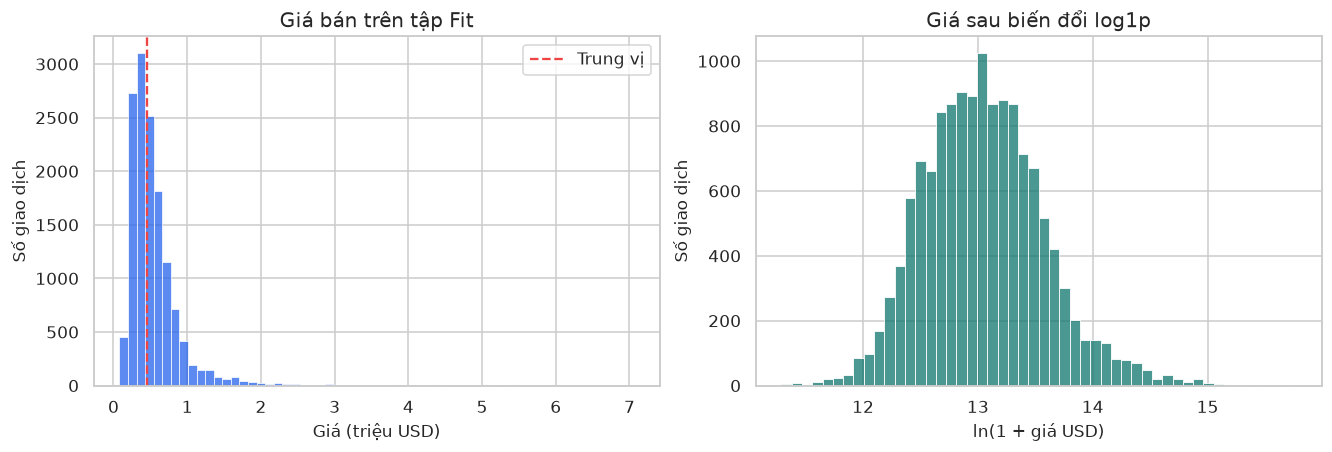

**Nhận xét từ Fit:** Giá trung bình **540,796 USD**, trung vị **452,000 USD**, độ lệch skew **3.66**. Giá có đuôi phải dài; biến đổi log làm giảm chênh lệch thang đo giữa nhà phổ thông và nhà đắt. Khi đánh giá, dự đoán phải được đổi trở lại USD.

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
sns.histplot(fit["price"] / 1_000_000, bins=60, ax=axes[0], color="#2563eb")
axes[0].axvline(fit["price"].median() / 1_000_000, color="#ef4444", linestyle="--", label="Trung vị")
axes[0].set(title="Giá bán trên tập Fit", xlabel="Giá (triệu USD)", ylabel="Số giao dịch")
axes[0].legend()
sns.histplot(np.log1p(fit["price"]), bins=50, ax=axes[1], color="#0f766e")
axes[1].set(title="Giá sau biến đổi log1p", xlabel="ln(1 + giá USD)", ylabel="Số giao dịch")
plt.show()
display(Markdown(
    f"**Nhận xét từ Fit:** Giá trung bình **{fit['price'].mean():,.0f} USD**, "
    f"trung vị **{fit['price'].median():,.0f} USD**, độ lệch skew **{fit['price'].skew():.2f}**. "
    "Giá có đuôi phải dài; biến đổi log làm giảm chênh lệch thang đo giữa nhà phổ thông và nhà đắt. "
    "Khi đánh giá, dự đoán phải được đổi trở lại USD."
))

### 2.7. Biểu đồ 2 — Diện tích và giá bán

**Câu hỏi:** Diện tích lớn hơn có đi cùng giá cao hơn không, và bốn đầu vào có thể giải thích hết giá không?
Lấy mẫu ngẫu nhiên tối đa 3.000 dòng Fit để tránh các điểm che nhau; thống kê tương quan vẫn tính trên toàn Fit.

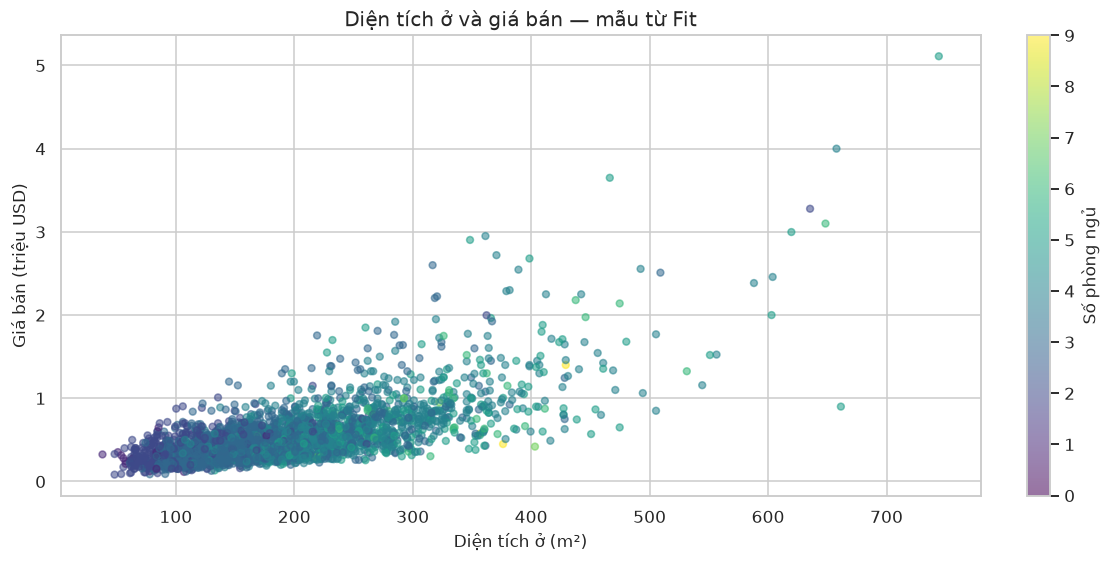

**Nhận xét:** Tương quan Pearson giữa diện tích và giá trên Fit là **0.695**. Các điểm có cùng khoảng diện tích vẫn phân tán theo giá; diện tích không đủ để xác định giá một mình. Đây là quan hệ quan sát, không phải bằng chứng nhân quả.

In [8]:
plot_sample = fit.sample(n=min(3000, len(fit)), random_state=SEED)
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
points = ax.scatter(plot_sample["dien_tich"], plot_sample["price"] / 1_000_000,
                    c=plot_sample["so_phong_ngu"], cmap="viridis", s=20, alpha=0.55)
fig.colorbar(points, ax=ax, label="Số phòng ngủ")
ax.set(title="Diện tích ở và giá bán — mẫu từ Fit", xlabel="Diện tích ở (m²)", ylabel="Giá bán (triệu USD)")
plt.show()
correlation = fit[["dien_tich", "price"]].corr().iloc[0, 1]
display(Markdown(
    f"**Nhận xét:** Tương quan Pearson giữa diện tích và giá trên Fit là **{correlation:.3f}**. "
    "Các điểm có cùng khoảng diện tích vẫn phân tán theo giá; diện tích không đủ để xác định giá một mình. "
    "Đây là quan hệ quan sát, không phải bằng chứng nhân quả."
))

### 2.8. Biểu đồ 3 — Giá và vị trí

**Câu hỏi:** Các vị trí trong cùng một quận có cùng mặt bằng giá không?
Biểu đồ tọa độ dùng màu theo thang log của giá, không phải bản đồ hành chính.
Mẫu điểm lấy từ Fit giống biểu đồ 2. Màu chỉ biểu diễn giá bán thực, không phải độ chính xác mô hình.

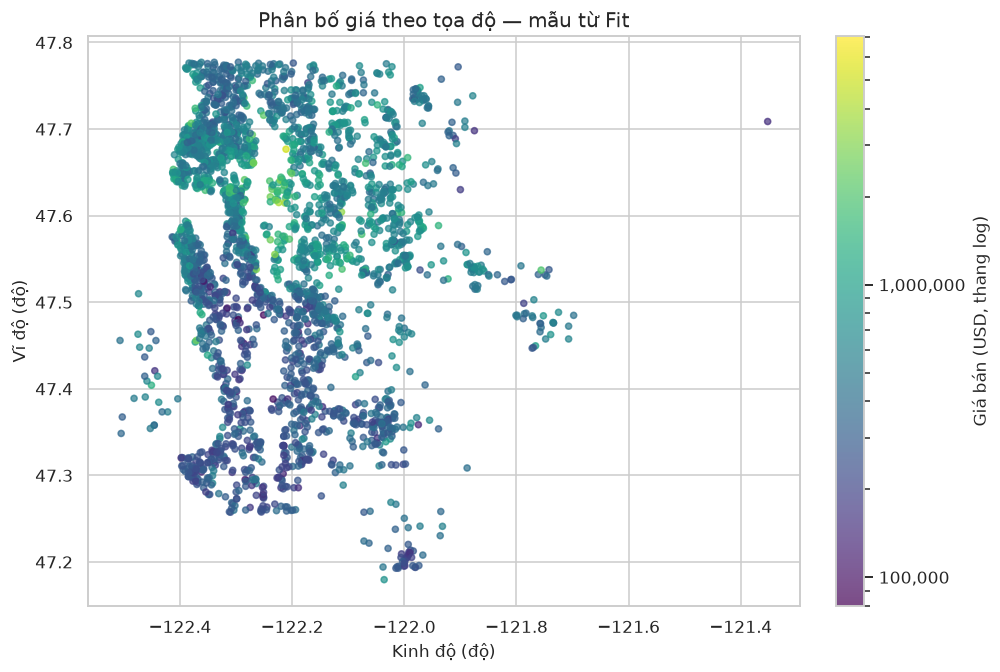

**Nhận xét:** Giá khác nhau giữa các vùng tọa độ; vị trí là tín hiệu cần giữ trong đầu vào. Quan hệ giá–tọa độ có thể thay đổi theo khu vực, là lý do thử mô hình cây bên cạnh hồi quy tuyến tính. Hình này chưa chứng minh khả năng dự đoán ở một thành phố chưa từng xuất hiện trong dữ liệu.

In [9]:
fig, ax = plt.subplots(figsize=(9, 6), layout="constrained")
points = ax.scatter(plot_sample["longitude"], plot_sample["latitude"], c=plot_sample["price"],
                    cmap="viridis", norm=LogNorm(vmin=fit["price"].min(), vmax=fit["price"].max()),
                    s=16, alpha=0.7)
colorbar = fig.colorbar(points, ax=ax, label="Giá bán (USD, thang log)")
colorbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set(title="Phân bố giá theo tọa độ — mẫu từ Fit", xlabel="Kinh độ (độ)", ylabel="Vĩ độ (độ)")
plt.show()
display(Markdown(
    "**Nhận xét:** Giá khác nhau giữa các vùng tọa độ; vị trí là tín hiệu cần giữ trong đầu vào. "
    "Quan hệ giá–tọa độ có thể thay đổi theo khu vực, là lý do thử mô hình cây bên cạnh hồi quy tuyến tính. "
    "Hình này chưa chứng minh khả năng dự đoán ở một thành phố chưa từng xuất hiện trong dữ liệu."
))

## 3. Lựa chọn mô hình AI/ML và đánh giá

### 3.1. Loại bài toán

Đây là **học có giám sát — hồi quy**. Ma trận `X` có bốn cột số; `y` là giá bán bằng USD.
Mỗi mẫu có nhãn giá thực. Mục tiêu là ước lượng giá một căn nhà chưa xuất hiện trong dữ liệu huấn luyện,
trong phạm vi địa lý và thời kỳ tương tự dataset.

### 3.2. Hai thuật toán và mô hình đối chứng

| Mô hình | Lý do lựa chọn và ưu điểm | Hạn chế |
|---|---|---|
| **Ridge** (hồi quy tuyến tính có phạt L2) | Nhanh, ít tham số, hệ số dễ khảo sát; làm mốc tuyến tính có điều chuẩn. Chuẩn hóa đầu vào vì diện tích và tọa độ khác thang đo. | Quan hệ tuyến tính trên thang nhãn đã biến đổi; khó mô tả ranh giới khu vực và tương tác phức tạp. |
| **XGBoost Regressor** | Học các cây nối tiếp để sửa sai; biểu diễn quan hệ phi tuyến và tương tác diện tích–phòng–vị trí. Cùng họ thuật toán với `retrain_model.py` của demo. | Phức tạp hơn, có nguy cơ học quá khớp và khó giải thích từng dự đoán; không đáng tin khi ngoại suy sang thị trường khác. |
| **Median baseline** | Luôn trả trung vị giá của tập học; giúp biết việc học đặc trưng có cải thiện so với dự đoán một hằng số không. | Không phân biệt các căn nhà; chỉ là đối chứng, không phải thuật toán chính được đề xuất. |

[Tài liệu Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html) ·
[Tài liệu XGBoost](https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.XGBRegressor).

**Cách huấn luyện:** Ridge và XGBoost học `log1p(price)` để giảm ảnh hưởng thang giá lệch phải;
`TransformedTargetRegressor` tự đổi kết quả về USD bằng `expm1`.
Log là biến đổi cố định, không ước lượng từ Test. Tối ưu lỗi trên log không đồng nghĩa tối ưu RMSE USD,
nên lựa chọn mô hình vẫn dùng metric trên giá gốc.

Các tham số được đặt trước: Ridge `alpha=1`; XGBoost 300 cây, độ sâu 5, learning rate 0,05,
subsample 0,9. Đây là cấu hình thực nghiệm vừa phải, không khẳng định tối ưu.
Không dùng Test để chọn số cây, độ sâu hay chọn mô hình.

### 3.3. Train / Validation / Test và chống rò rỉ

Phép chia theo mã nhà đã thực hiện ở mục 2.5:

1. Huấn luyện từng ứng viên trên **Fit**, đánh giá trên **Validation**.
2. Chọn ứng viên có **RMSE Validation thấp nhất**, khóa lựa chọn.
3. Huấn luyện lại ứng viên đó trên toàn bộ **Train = Fit + Validation** (khoảng 80% dữ liệu).
4. Đánh giá một lần trên **Test** giữ riêng (khoảng 20%), cùng baseline học trên Train.

Imputer và scaler nằm trong Pipeline: ở mỗi lần `.fit()`, chúng chỉ học từ tập được phép huấn luyện.
CSV hiện tại không có ô thiếu; sau kiểm tra miền cũng không còn giá trị thiếu. Imputer trung vị là bước dự phòng,
không thay thế nhãn và không có nghĩa bài này đã phát hiện ô thiếu. Scaler chỉ cần cho Ridge;
XGBoost không cần chuẩn hóa thang đo.

Chia ngẫu nhiên theo nhà chưa bảo đảm độc lập theo khu phố/thời gian. Nếu mục tiêu chuyển thành dự đoán
giá tương lai hoặc vùng mới, cần tách theo thời gian/vùng và đánh giá lại.

### 3.4. Metric đánh giá

Gọi $y_i$ là giá thật, $\hat y_i$ là giá dự đoán, $n$ là số mẫu đánh giá:

- **MAE** $=\frac{1}{n}\sum |y_i-\hat y_i|$: sai lệch tuyệt đối trung bình, đơn vị USD, dễ diễn giải.
- **RMSE** $=\sqrt{\frac{1}{n}\sum(y_i-\hat y_i)^2}$: phạt mạnh sai số lớn; dùng làm tiêu chí chọn mô hình
  vì sai giá rất lớn ở một số căn cũng quan trọng.
- **R²** $=1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$: so với dự đoán bằng trung bình của tập đánh giá.
  Càng gần 1 càng tốt; có thể âm và **không phải tỷ lệ phần trăm dự đoán đúng**.

MAE và RMSE càng thấp càng tốt. Tất cả được tính sau khi đưa dự đoán về **USD**, không báo lỗi log như lỗi tiền.
Baseline dùng trung vị để có đối chứng đơn giản, còn công thức R² vẫn dùng trung bình theo định nghĩa.

In [10]:
X_fit, y_fit = fit[FEATURES], fit["price"]
X_validation, y_validation = validation[FEATURES], validation["price"]
X_train, y_train = development[FEATURES], development["price"]
X_test, y_test = test[FEATURES], test["price"]

ridge_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regressor", Ridge(alpha=1.0)),
])
xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", XGBRegressor(
        n_estimators=300, max_depth=5, learning_rate=0.05,
        subsample=0.9, colsample_bytree=1.0, reg_lambda=1.0,
        objective="reg:squarederror", tree_method="hist", random_state=SEED, n_jobs=2,
    )),
])
templates = {
    "Median baseline": DummyRegressor(strategy="median"),
    "Ridge (log target)": TransformedTargetRegressor(
        regressor=ridge_pipeline, func=np.log1p, inverse_func=np.expm1
    ),
    "XGBoost (log target)": TransformedTargetRegressor(
        regressor=xgb_pipeline, func=np.log1p, inverse_func=np.expm1
    ),
}

def evaluate(y_true, predicted):
    predicted = np.asarray(predicted, dtype=float)
    assert predicted.shape == np.asarray(y_true).shape
    assert np.isfinite(predicted).all()
    return {
        "MAE (USD)": mean_absolute_error(y_true, predicted),
        "RMSE (USD)": np.sqrt(mean_squared_error(y_true, predicted)),
        "R²": r2_score(y_true, predicted),
    }

validation_rows = []
validation_models = {}
for name, template in templates.items():
    model = clone(template)
    model.fit(X_fit, y_fit)
    validation_models[name] = model
    validation_rows.append({"Mô hình": name, **evaluate(y_validation, model.predict(X_validation))})
validation_results = pd.DataFrame(validation_rows).set_index("Mô hình").sort_values("RMSE (USD)")
selected_name = validation_results.index[0]
display(validation_results)
print("Lựa chọn đã khóa bằng Validation:", selected_name)

,MAE (USD),RMSE (USD),R²
Mô hình,,,
XGBoost (log target),"84,718.940","169,032.900",0.790
Ridge (log target),"141,047.896","291,574.537",0.376
Median baseline,"220,340.945","379,175.177",-0.056


Lựa chọn đã khóa bằng Validation: XGBoost (log target)


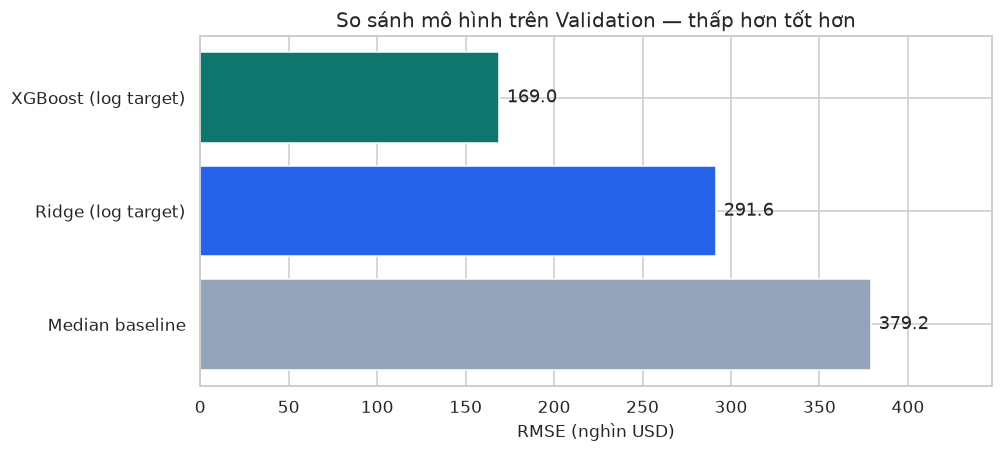

**Lựa chọn:** XGBoost (log target), RMSE Validation **169,033 USD**. Lựa chọn này được quyết định trước khi xem điểm Test; không thay mô hình dựa trên bảng Test tiếp theo.

In [11]:
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
values = validation_results["RMSE (USD)"] / 1000
bars = ax.barh(values.index, values.to_numpy(), color=["#0f766e", "#2563eb", "#94a3b8"])
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.1f", padding=5)
ax.set_xlim(0, values.max() * 1.18)
ax.set(title="So sánh mô hình trên Validation — thấp hơn tốt hơn", xlabel="RMSE (nghìn USD)", ylabel="")
plt.show()
display(Markdown(
    f"**Lựa chọn:** {selected_name}, RMSE Validation **{validation_results.loc[selected_name, 'RMSE (USD)']:,.0f} USD**. "
    "Lựa chọn này được quyết định trước khi xem điểm Test; không thay mô hình dựa trên bảng Test tiếp theo."
))

### 3.5. Đánh giá cuối trên Test

Huấn luyện lại lựa chọn đã khóa trên cả Fit và Validation. Test chỉ cung cấp điểm đánh giá cuối;
không quay lại điều chỉnh mô hình theo những sai số nhìn thấy ở bước này.

In [12]:
final_model = clone(templates[selected_name]).fit(X_train, y_train)
test_predictions = final_model.predict(X_test)
baseline_model = DummyRegressor(strategy="median").fit(X_train, y_train)
baseline_predictions = baseline_model.predict(X_test)
test_results = pd.DataFrame([
    {"Mô hình": selected_name, **evaluate(y_test, test_predictions)},
    {"Mô hình": "Median baseline", **evaluate(y_test, baseline_predictions)},
]).set_index("Mô hình")
display(test_results)
print(f"Train cuối: {len(X_train):,} giao dịch; Test: {len(X_test):,} giao dịch.")

,MAE (USD),RMSE (USD),R²
Mô hình,,,
XGBoost (log target),"81,452.155","155,353.929",0.815
Median baseline,"221,450.203","370,519.334",-0.055


Train cuối: 17,284 giao dịch; Test: 4,326 giao dịch.


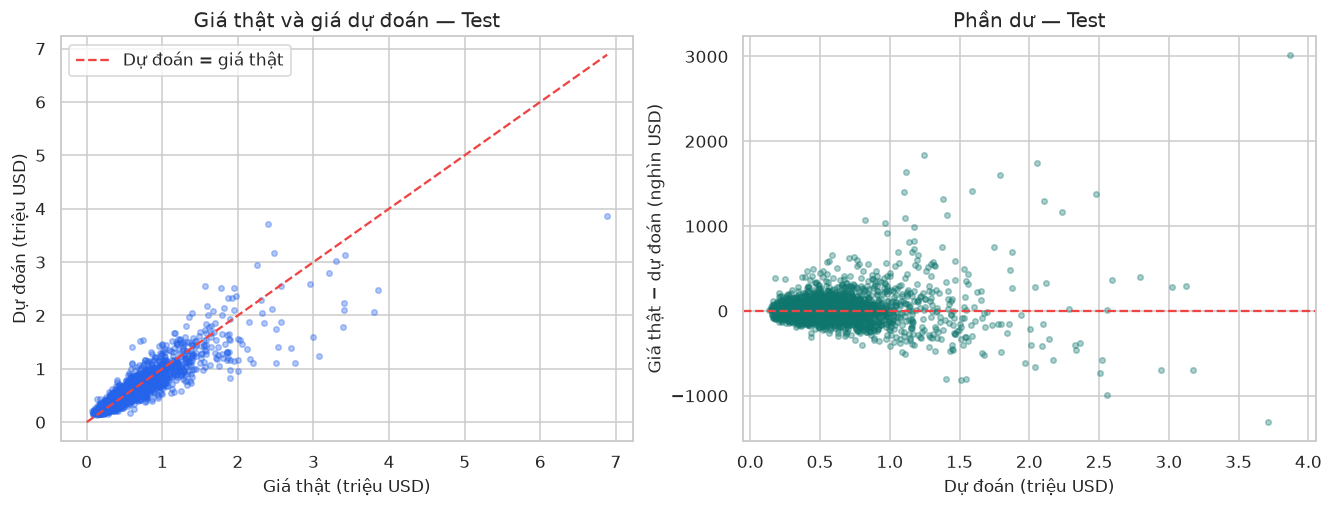

**Đọc biểu đồ:** Điểm gần đường chéo có dự đoán sát thực tế. Phần dư dương nghĩa là dự đoán thấp hơn giá thật; phần dư âm nghĩa là dự đoán cao hơn. Các sai số lớn còn lại nhắc rằng bốn đầu vào chưa mô tả hết một căn nhà. Biểu đồ Test này phục vụ báo cáo, không được dùng để chọn lại mô hình trong cùng thực nghiệm.

In [13]:
errors = np.asarray(y_test) - test_predictions
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
axes[0].scatter(np.asarray(y_test) / 1_000_000, test_predictions / 1_000_000, s=13, alpha=0.35, color="#2563eb")
upper = max(float(np.max(y_test)), float(np.max(test_predictions))) / 1_000_000
axes[0].plot([0, upper], [0, upper], "--", color="#ef4444", label="Dự đoán = giá thật")
axes[0].set(title="Giá thật và giá dự đoán — Test", xlabel="Giá thật (triệu USD)", ylabel="Dự đoán (triệu USD)")
axes[0].legend()
axes[1].scatter(test_predictions / 1_000_000, errors / 1000, s=13, alpha=0.35, color="#0f766e")
axes[1].axhline(0, linestyle="--", color="#ef4444")
axes[1].set(title="Phần dư — Test", xlabel="Dự đoán (triệu USD)", ylabel="Giá thật − dự đoán (nghìn USD)")
plt.show()
display(Markdown(
    "**Đọc biểu đồ:** Điểm gần đường chéo có dự đoán sát thực tế. Phần dư dương nghĩa là dự đoán thấp hơn giá thật; "
    "phần dư âm nghĩa là dự đoán cao hơn. Các sai số lớn còn lại nhắc rằng bốn đầu vào chưa mô tả hết một căn nhà. "
    "Biểu đồ Test này phục vụ báo cáo, không được dùng để chọn lại mô hình trong cùng thực nghiệm."
))

### 3.6. Minh họa dự đoán theo bốn trường của demo

Chọn cố định năm dòng đầu của Test để đối chiếu, không chọn riêng các trường hợp đoán tốt.
Các giá trị dưới đây đều bằng USD và thuộc phạm vi King County trong dataset.
Đây là mô hình thực nghiệm trong bộ nhớ của notebook; không xuất thành `house_model.pkl` của luồng VND.

In [14]:
example = X_test.head(5).copy()
example["Giá thật (USD)"] = y_test.head(5).to_numpy()
example["Dự đoán (USD)"] = final_model.predict(example[FEATURES])
example["Sai lệch tuyệt đối (USD)"] = (
    example["Giá thật (USD)"] - example["Dự đoán (USD)"]
).abs()
display(example)

,dien_tich,so_phong_ngu,latitude,longitude,Giá thật (USD),Dự đoán (USD),Sai lệch tuyệt đối (USD)
3,182.090,4,47.521,-122.393,"604,000.000","558,154.688","45,845.312"
4,156.077,3,47.617,-122.045,"510,000.000","492,210.000","17,790.000"
10,330.735,3,47.601,-122.145,"662,500.000","1,027,098.062","364,598.062"
21,283.354,3,47.532,-122.233,"2,000,000.000","967,590.375","1,032,409.625"
24,227.612,3,47.374,-122.172,"329,000.000","333,942.188","4,942.188"


## 4. Kết luận và hướng phát triển

Bảng dưới và đoạn kết luận được tạo từ kết quả thực thi, không điền sẵn điểm đánh giá.

In [15]:
score = test_results.loc[selected_name]
baseline_score = test_results.loc["Median baseline"]
rmse_change = (1 - score["RMSE (USD)"] / baseline_score["RMSE (USD)"]) * 100
change_text = (f"giảm {rmse_change:.1f}%" if rmse_change >= 0 else f"tăng {-rmse_change:.1f}%")
display(Markdown(
    f"- **Dữ liệu:** {len(raw):,} giao dịch, {raw.shape[1]} thuộc tính gốc; "
    f"còn **{len(clean):,} giao dịch** trong miền đầu vào đã chọn.\n"
    f"- **Chất lượng dữ liệu:** {int(raw.isna().sum().sum())} ô thiếu, "
    f"{int(raw.duplicated().sum())} dòng trùng hoàn toàn; "
    f"{int(raw.duplicated('id').sum())} dòng lặp mã nhà được xử lý bằng chia nhóm.\n"
    f"- **Mô hình được chọn bằng Validation:** {selected_name}.\n"
    f"- **Test:** MAE **{score['MAE (USD)']:,.0f} USD**, RMSE **{score['RMSE (USD)']:,.0f} USD**, "
    f"R² **{score['R²']:.3f}**. RMSE {change_text} so với baseline trung vị.\n"
    "- **Giới hạn:** Đây là điểm trên một lần chia theo mã nhà, chưa có khoảng tin cậy hay kiểm thử thị trường khác. "
    "Không diễn giải R² thành tỷ lệ dự đoán đúng và không coi đây là giá nhà hiện tại ở Việt Nam."
))

- **Dữ liệu:** 21,613 giao dịch, 21 thuộc tính gốc; còn **21,610 giao dịch** trong miền đầu vào đã chọn.
- **Chất lượng dữ liệu:** 0 ô thiếu, 0 dòng trùng hoàn toàn; 177 dòng lặp mã nhà được xử lý bằng chia nhóm.
- **Mô hình được chọn bằng Validation:** XGBoost (log target).
- **Test:** MAE **81,452 USD**, RMSE **155,354 USD**, R² **0.815**. RMSE giảm 58.1% so với baseline trung vị.
- **Giới hạn:** Đây là điểm trên một lần chia theo mã nhà, chưa có khoảng tin cậy hay kiểm thử thị trường khác. Không diễn giải R² thành tỷ lệ dự đoán đúng và không coi đây là giá nhà hiện tại ở Việt Nam.

**Hướng phát triển:** Bổ sung chất lượng, tuổi nhà, phòng tắm và diện tích đất nếu mở rộng đầu vào demo;
thử GroupKFold chỉ trong tập Train để đánh giá độ ổn định; kiểm thử theo thời gian hoặc tách khu vực
khi đổi mục tiêu sử dụng; thu thập dữ liệu cùng thị trường và cùng đơn vị trước khi triển khai thực tế.
Nếu tiếp tục tối ưu từ những lỗi Test đã nhìn thấy, cần một tập kiểm thử mới cho lần kết luận tiếp theo.

### Đối chiếu yêu cầu bàn giao

| Yêu cầu | Vị trí trong notebook |
|---|---|
| Nguồn, số mẫu, đặc trưng, độ phù hợp, hạn chế | Mục 1 |
| Kích thước, giá trị thiếu, trùng lặp | Mục 2.1–2.2 |
| Làm sạch bằng NumPy/Pandas; bỏ thuộc tính có lý do | Mục 2.3–2.4 |
| Ít nhất 2 biểu đồ có ý nghĩa | 3 biểu đồ khám phá ở mục 2.6–2.8 |
| Loại bài toán; ít nhất 2 thuật toán, ưu/nhược điểm | Mục 3.1–3.2 |
| Cách chia Train/Test và kiểm soát rò rỉ | Mục 2.5 và 3.3 |
| Metric và lý do chọn | Mục 3.4 |
| Kết quả chạy và nhận xét | Mục 3.5–4 |

### Tài liệu tham khảo

1. [Kaggle — House Sales in King County, USA](https://www.kaggle.com/datasets/harlfoxem/housesalesprediction).
2. [GeoDa Center — King County Home Sales](https://geodacenter.github.io/data-and-lab/KingCounty-HouseSales2015/).
3. [scikit-learn — GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html).
4. [scikit-learn — Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html).
5. [XGBoost — XGBRegressor](https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.XGBRegressor).

**Tên file bàn giao:** `TeamWork_PP_Nhom8.ipynb`.

## 5 Phân tích mở rộng và ứng dụng tích hợp

Đây là thí nghiệm dùng cho báo cáo, PowerPoint và ứng dụng tham khảo King County. Dữ liệu vẫn là snapshot King County đã kiểm tra SHA-256 ở mục 1. Nhãn học máy là giá USD, kết quả hiển thị VND theo snapshot tỷ giá Vietcombank có lưu nguồn và ngày.

Các đặc trưng bổ sung gồm diện tích đất, phòng tắm, số tầng, chất lượng, tình trạng, cảnh quan, ven nước, tuổi nhà, cải tạo, mã bưu chính và tháng giao dịch. Giá/m² được tính **sau dự đoán**, không đưa vào X vì dẫn xuất từ nhãn. Không dùng `sqft_living15` và `sqft_lot15` khi chưa xác nhận vintage lịch sử của hai biến này.

Train 05–10/2014, validation 11–12/2014, hiệu chỉnh khoảng 01–02/2015 và test 03–05/2015. Loại giao dịch cũ của mã nhà thuộc tập phía sau để các tập không chung căn. Chọn mô hình chỉ bằng RMSE validation. Mô hình phục vụ là chính bản train + validation đã được đánh giá, không fit lại trên calibration hoặc test.

In [16]:
import sys, json
sys.path.insert(0, str(demo_root / "real_estate_ai"))
from backend.train_kingcounty import train as train_integrated
from backend.kingcounty import ARTIFACTS, load_bundle, estimate_property
integrated_metadata = train_integrated(import_db=False)
display(pd.DataFrame(integrated_metadata["splits"]).T)
display(pd.read_csv(ARTIFACTS / "validation_metrics.csv"))
print("Mô hình đã khóa:", integrated_metadata["selected_model"])
print("Các dòng bị loại:", integrated_metadata["audit"]["invalid_rows"])
print("Giao dịch cũ bị purge:", integrated_metadata["purged_rows"])

VALIDATION Median baseline {'model': 'Median baseline', 'mae_usd': 217277.04186632342, 'rmse_usd': 361664.4960319957, 'r2': -0.0376643595920747, 'median_ape': 0.344971280125421, 'mape': 0.43828076182525194, 'within_10pct': 0.15948124780932352, 'within_20pct': 0.2961794602173151}


VALIDATION Ridge 4 biến {'model': 'Ridge 4 biến', 'mae_usd': 132920.9684879747, 'rmse_usd': 230977.02718344014, 'r2': 0.5767638829354513, 'median_ape': 0.18635914098485581, 'mape': 0.24197116827626858, 'within_10pct': 0.28391167192429023, 'within_20pct': 0.5289169295478444}


VALIDATION XGBoost 4 biến {'model': 'XGBoost 4 biến', 'mae_usd': 79799.37093629513, 'rmse_usd': 161702.9541447814, 'r2': 0.7925654685516653, 'median_ape': 0.10265860294117647, 'mape': 0.14207376947259204, 'within_10pct': 0.4854539081668419, 'within_20pct': 0.7690150718541886}


VALIDATION XGBoost nhà và vị trí {'model': 'XGBoost nhà và vị trí', 'mae_usd': 63674.78119523309, 'rmse_usd': 115485.85820061115, 'r2': 0.8941958363454593, 'median_ape': 0.08577571428571429, 'mape': 0.11745481892334801, 'within_10pct': 0.5713284262180162, 'within_20pct': 0.8310550297932001}


SELECTED XGBoost nhà và vị trí TEST {'mae_usd': 76538.43655756579, 'rmse_usd': 131886.2846693789, 'r2': 0.8733815340059443, 'median_ape': 0.10433858423051956, 'mape': 0.13222009407783264, 'within_10pct': 0.4789473684210526, 'within_20pct': 0.7953684210526316, 'interval_coverage': 0.9084210526315789, 'median_interval_width_usd': 264360.3125} SPLITS {'test': {'rows': 4750, 'houses': 4750, 'first_date': '2015-03-01', 'last_date': '2015-05-27'}, 'calibration': {'rows': 2218, 'houses': 2218, 'first_date': '2015-01-02', 'last_date': '2015-02-28'}, 'validation': {'rows': 2853, 'houses': 2853, 'first_date': '2014-11-01', 'last_date': '2014-12-31'}, 'train': {'rows': 11596, 'houses': 11586, 'first_date': '2014-05-02', 'last_date': '2014-10-31'}}


,rows,houses,first_date,last_date
test,4750,4750,2015-03-01,2015-05-27
calibration,2218,2218,2015-01-02,2015-02-28
validation,2853,2853,2014-11-01,2014-12-31
train,11596,11586,2014-05-02,2014-10-31


,model,mae_usd,rmse_usd,r2,median_ape,mape,within_10pct,within_20pct
0,XGBoost nhà và vị trí,"63,674.781","115,485.858",0.894,0.086,0.117,0.571,0.831
1,XGBoost 4 biến,"79,799.371","161,702.954",0.793,0.103,0.142,0.485,0.769
2,Ridge 4 biến,"132,920.968","230,977.027",0.577,0.186,0.242,0.284,0.529
3,Median baseline,"217,277.042","361,664.496",-0.038,0.345,0.438,0.159,0.296


Mô hình đã khóa: XGBoost nhà và vị trí
Các dòng bị loại: 29
Giao dịch cũ bị purge: 167


### 5 1 Bằng chứng về diện tích phòng và môi trường

Biểu đồ khám phá dưới đây chỉ dùng tập train. Trung vị giữa các nhóm thể hiện quan hệ quan sát, không chứng minh tăng thêm một phòng sẽ làm giá tăng đúng bằng chênh lệch giữa hai cột. Chất lượng, diện tích và vị trí có thể cùng thay đổi.

Created 11 figures and editable chart data: E:\Workspace\Python_k18\TieuLuan_CuoiKy\real_estate_ai\artifacts\kingcounty\charts


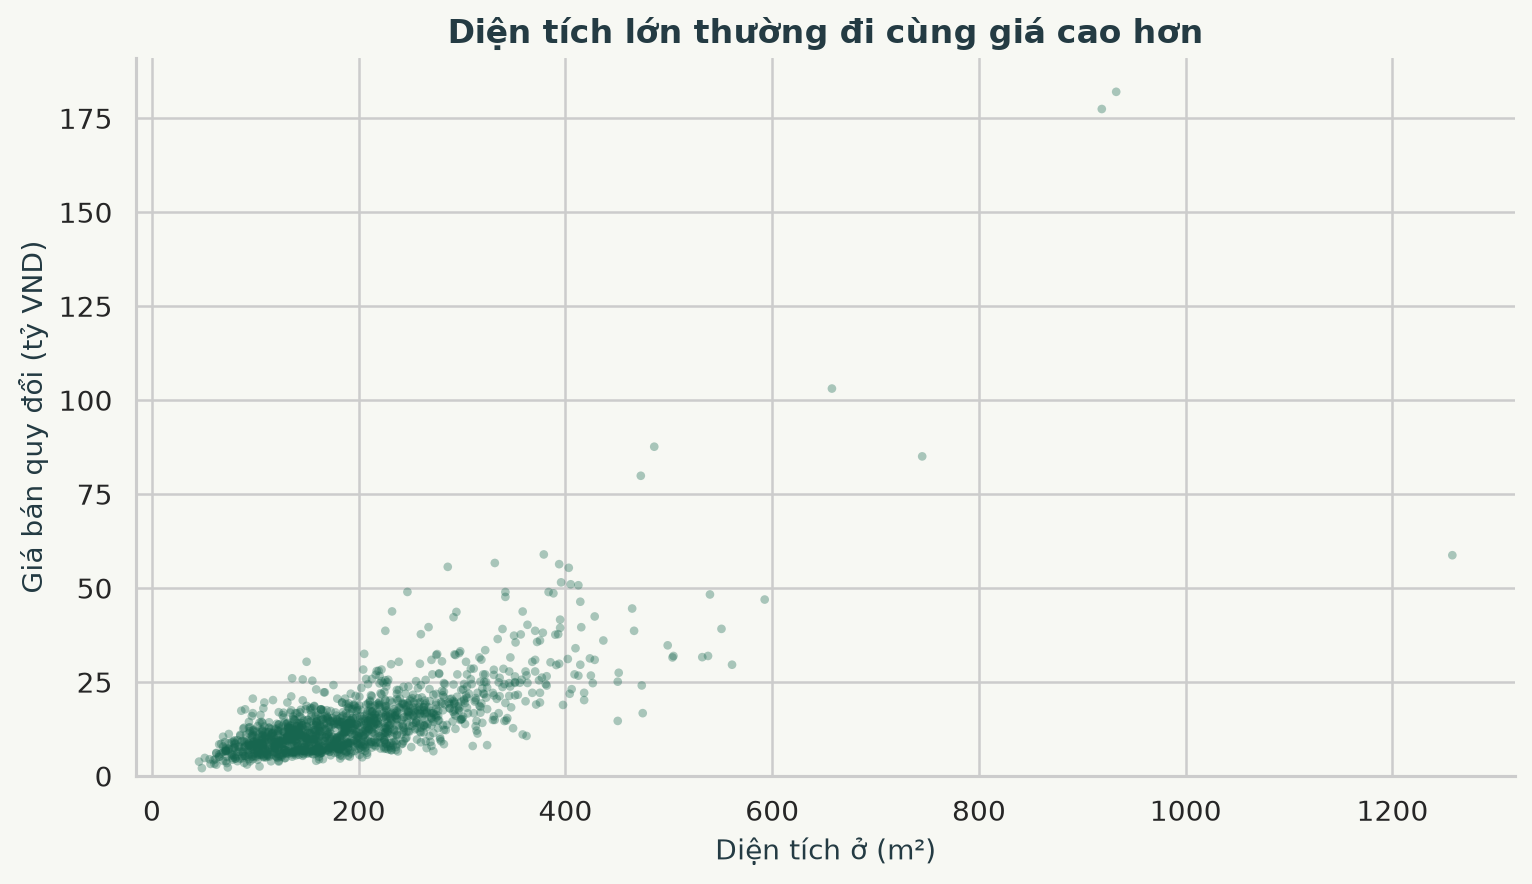

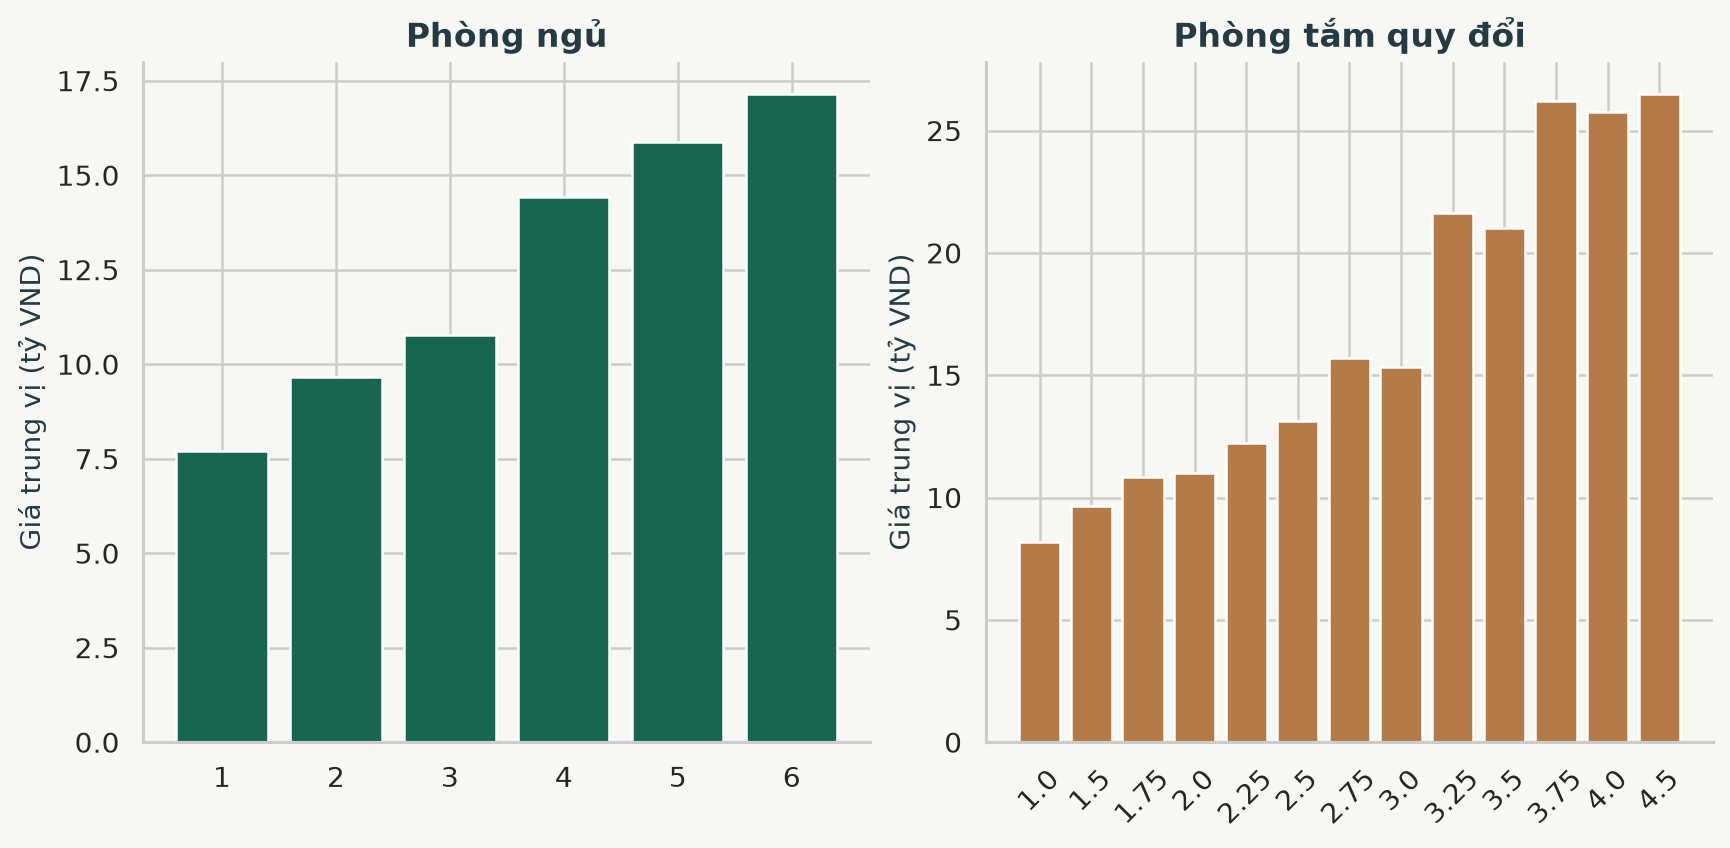

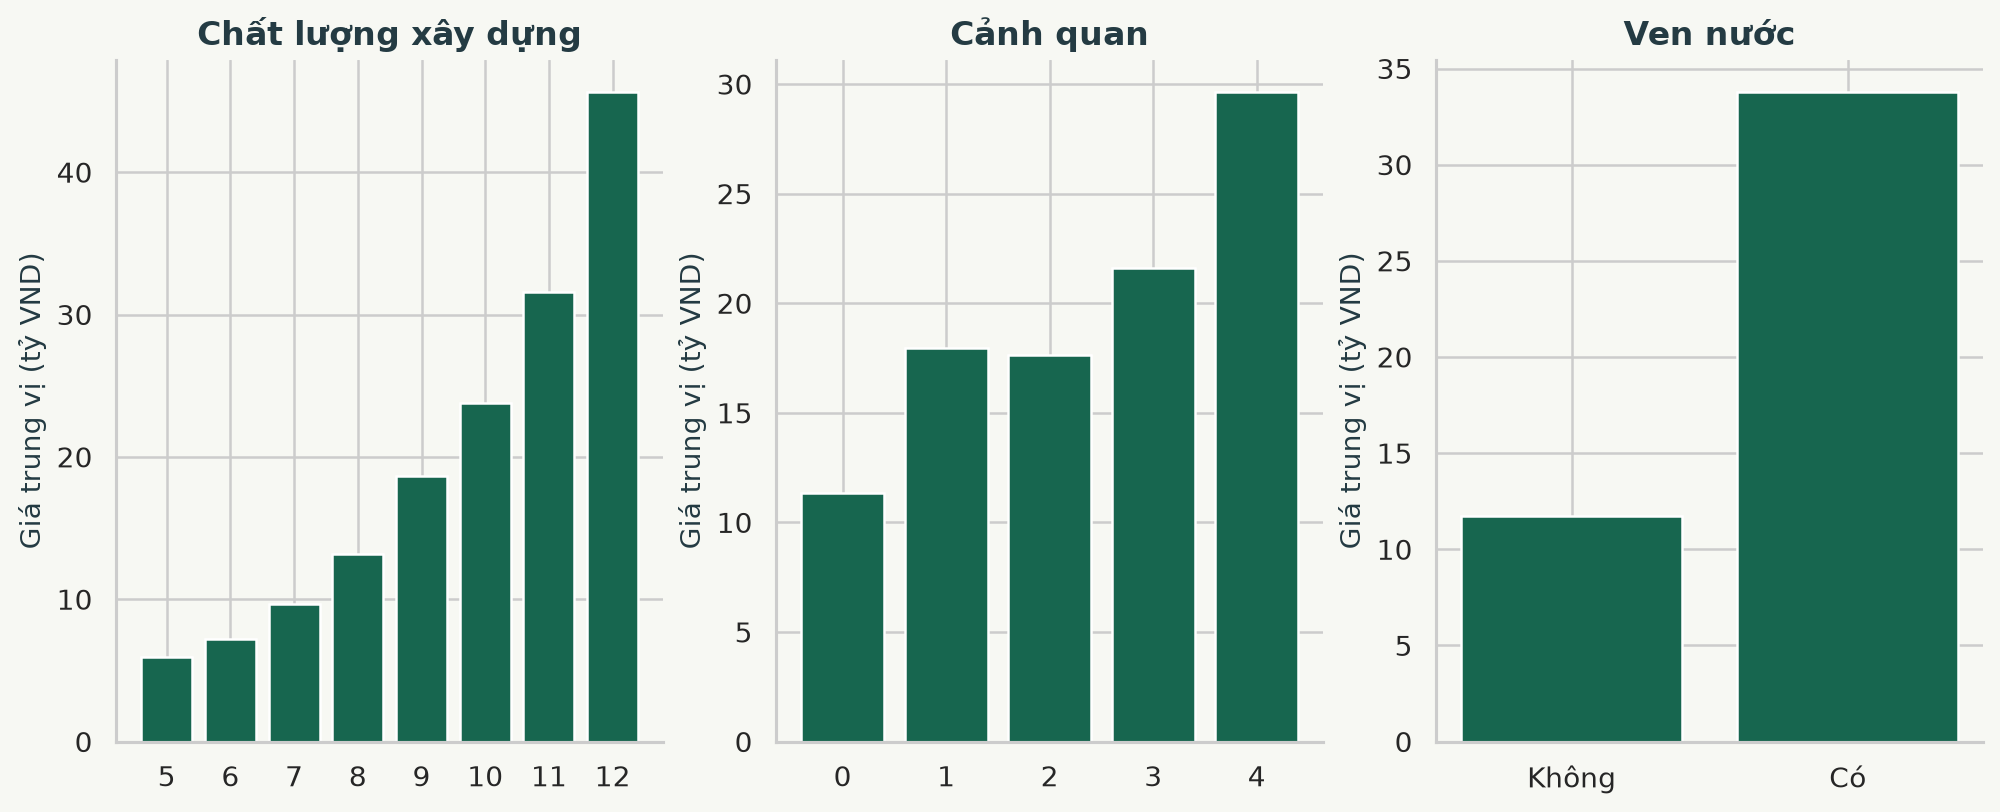

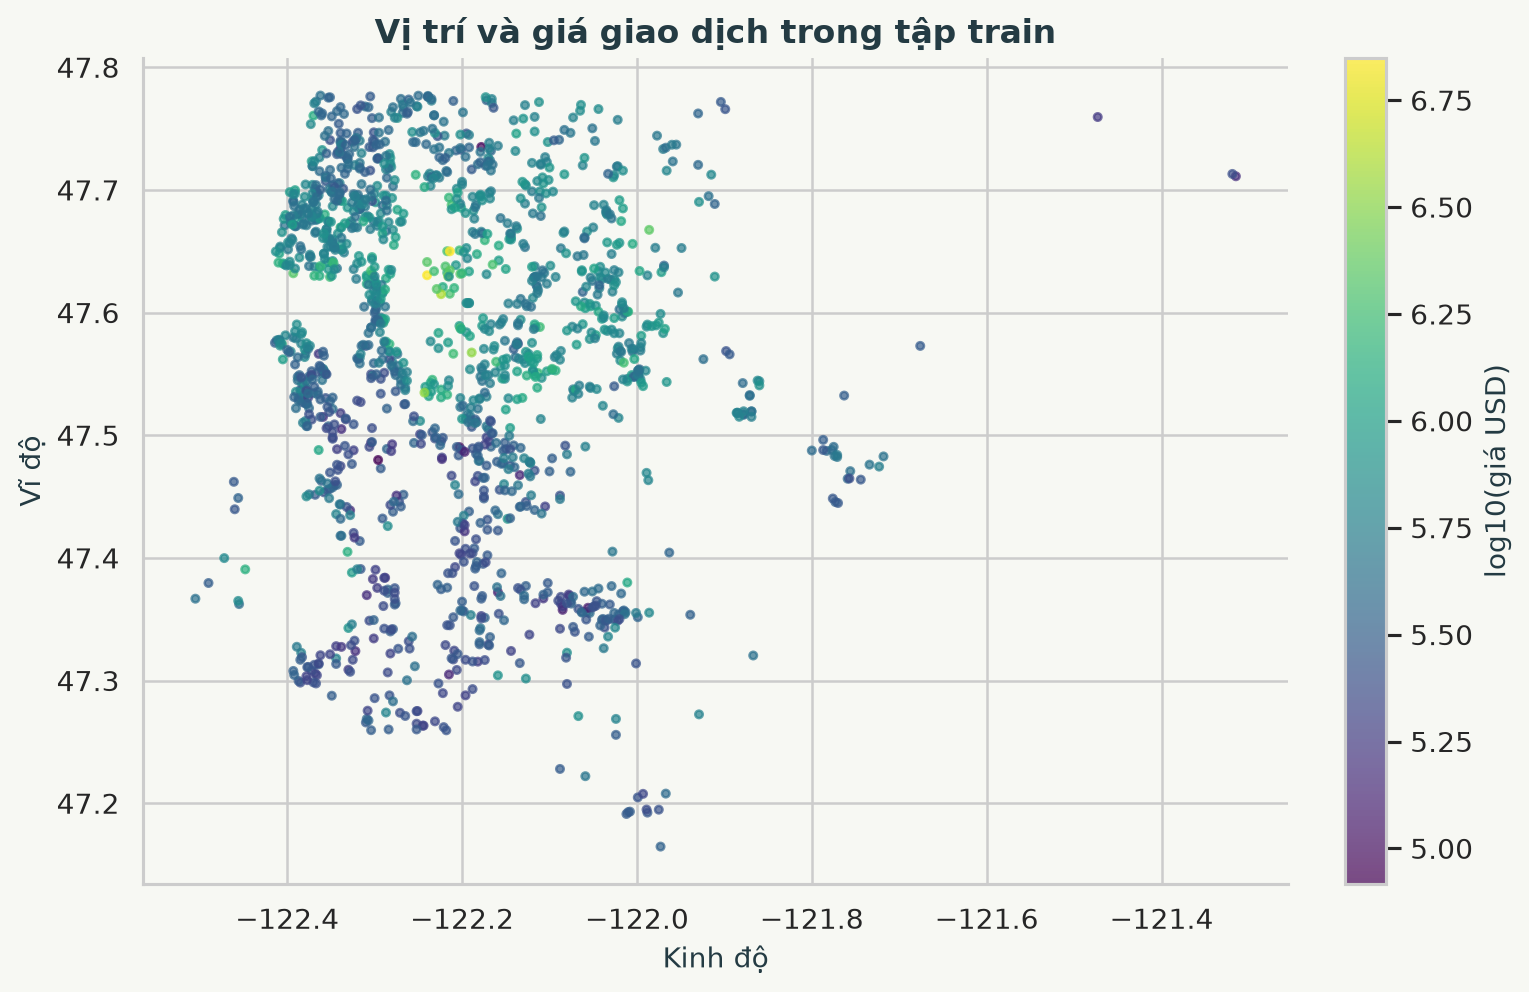

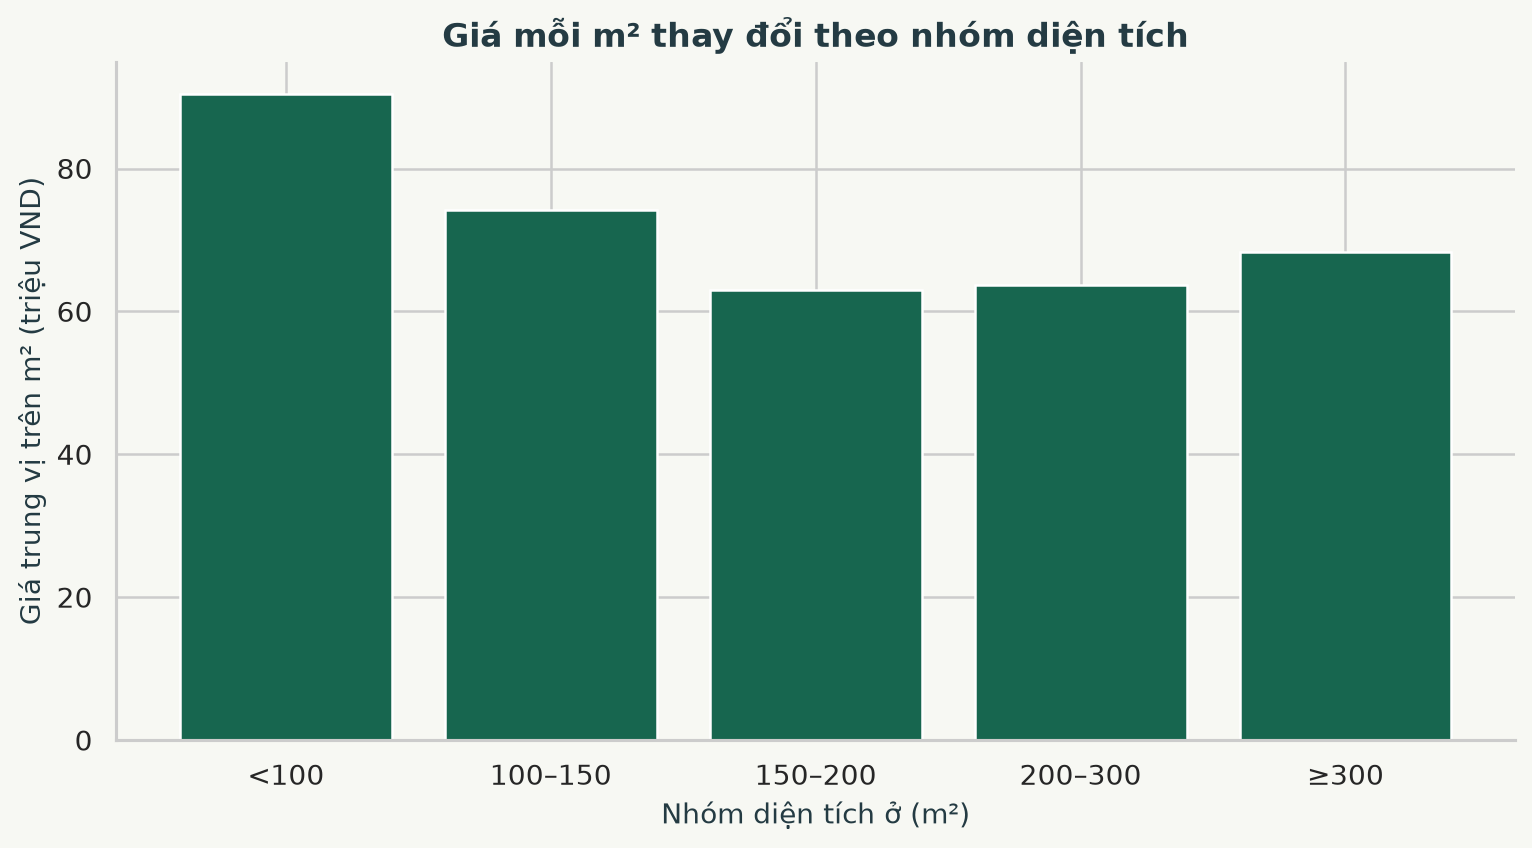

In [17]:
import importlib.util
from IPython.display import Image
_spec = importlib.util.spec_from_file_location("kc_evidence", demo_root / "scripts/build_kingcounty_evidence.py")
_evidence_module = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(_evidence_module)
_evidence_module.main()
for _chart in ["area_price", "bedrooms_bathrooms", "quality_environment", "location", "price_per_m2"]:
    display(Image(filename=str(ARTIFACTS / "charts" / (_chart + ".png"))))

### 5 2 Trường học và cửa hàng

Dataset gốc không có trường học, cửa hàng hay khoảng cách tiện ích. Mã nguồn hỗ trợ snapshot OpenStreetMap trước ngày 02/05/2014, lưu thời điểm, checksum và giấy phép. Chỉ khi snapshot xác minh được mới tạo các biến khoảng cách và đưa mô hình thêm tiện ích vào so sánh validation.

Nếu nguồn ngoài không truy cập được, kết quả ghi rõ chưa có dữ liệu. Không suy ra khoảng cách từ mã bưu chính, không lấy dữ liệu vị trí hiện tại làm bằng chứng năm 2014 và không tự điền con số. Khoảng cách đường chim bay cũng không xác định quyền tuyển sinh hay quãng đường đi bộ.

Có snapshot tiện ích: False
Số địa điểm theo loại: {}


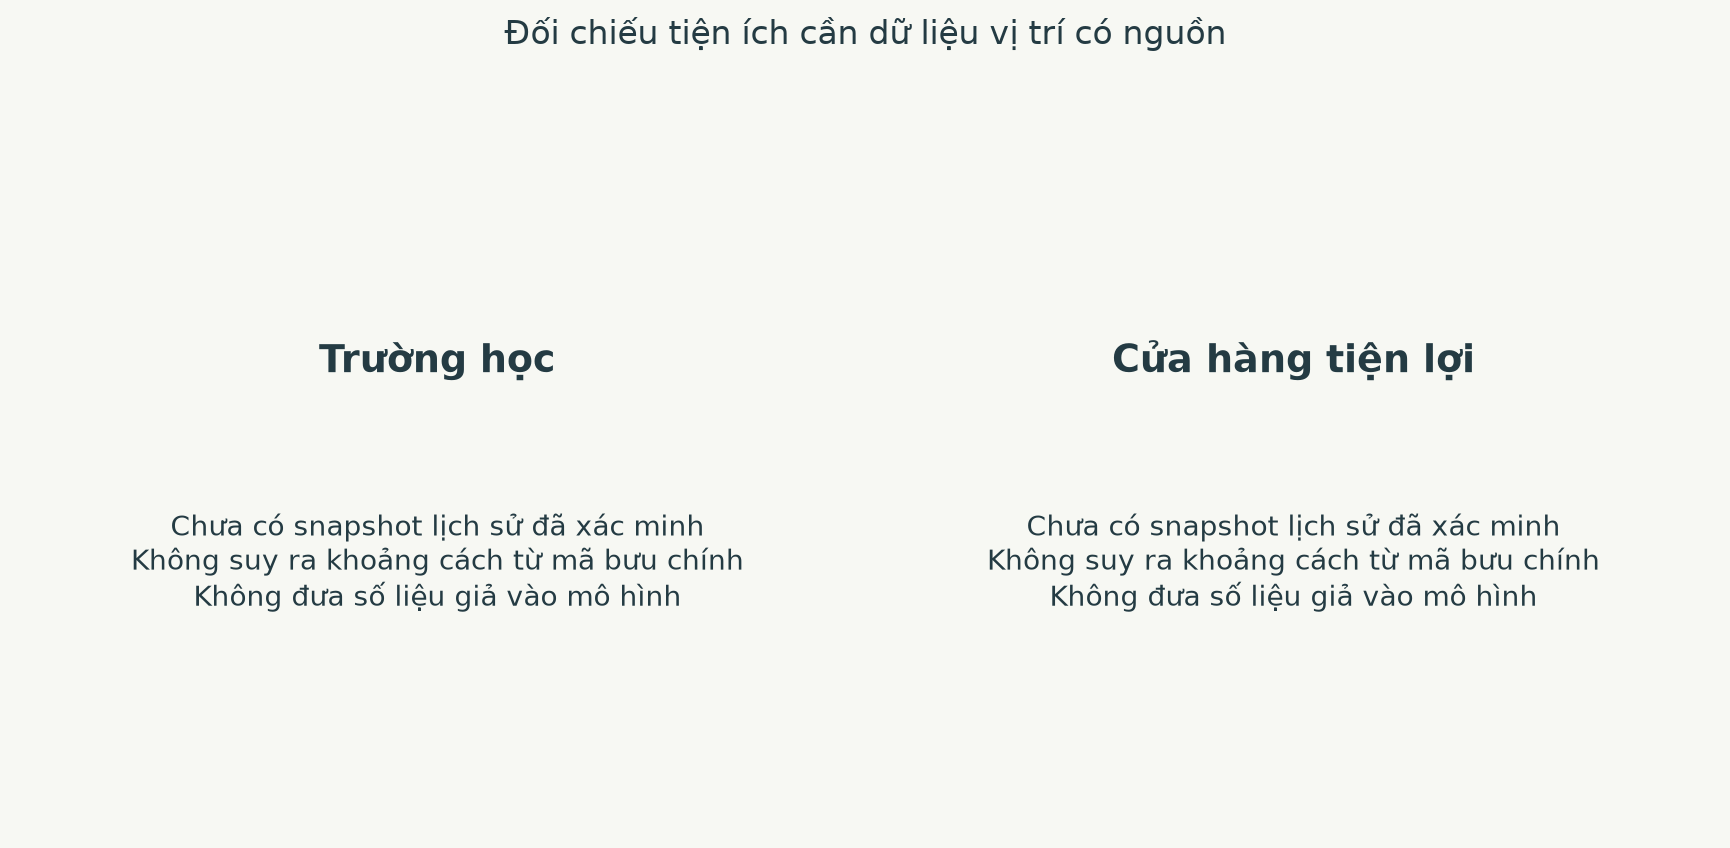

In [18]:
print("Có snapshot tiện ích:", integrated_metadata["poi_available"])
print("Số địa điểm theo loại:", integrated_metadata["poi_counts"])
display(Image(filename=str(ARTIFACTS / "charts/amenities.png")))

### 5 3 Kiểm thử theo thời gian và độ bất định

Khoảng dự đoán sử dụng phân vị hiệu chỉnh của sai số tuyệt đối trên log(1 + USD) ở tập calibration. Mức 90% là danh nghĩa; dữ liệu theo thời gian có thể thay đổi phân phối nên phải báo cáo độ phủ thực tế trên test. R² không phải tỷ lệ dự đoán đúng. Tỷ lệ nằm trong sai lệch ±10% và ±20% được tính trực tiếp từ từng giao dịch.

,mae_usd,rmse_usd,r2,median_ape,mape,within_10pct,within_20pct,interval_coverage,median_interval_width_usd
Mô hình được chọn,"76,538.437","131,886.285",0.873,0.104,0.132,0.479,0.795,0.908,"264,360.312"
Median baseline,"226,484.596","385,065.971",-0.079,0.331,0.410,0.156,0.313,NaN,NaN


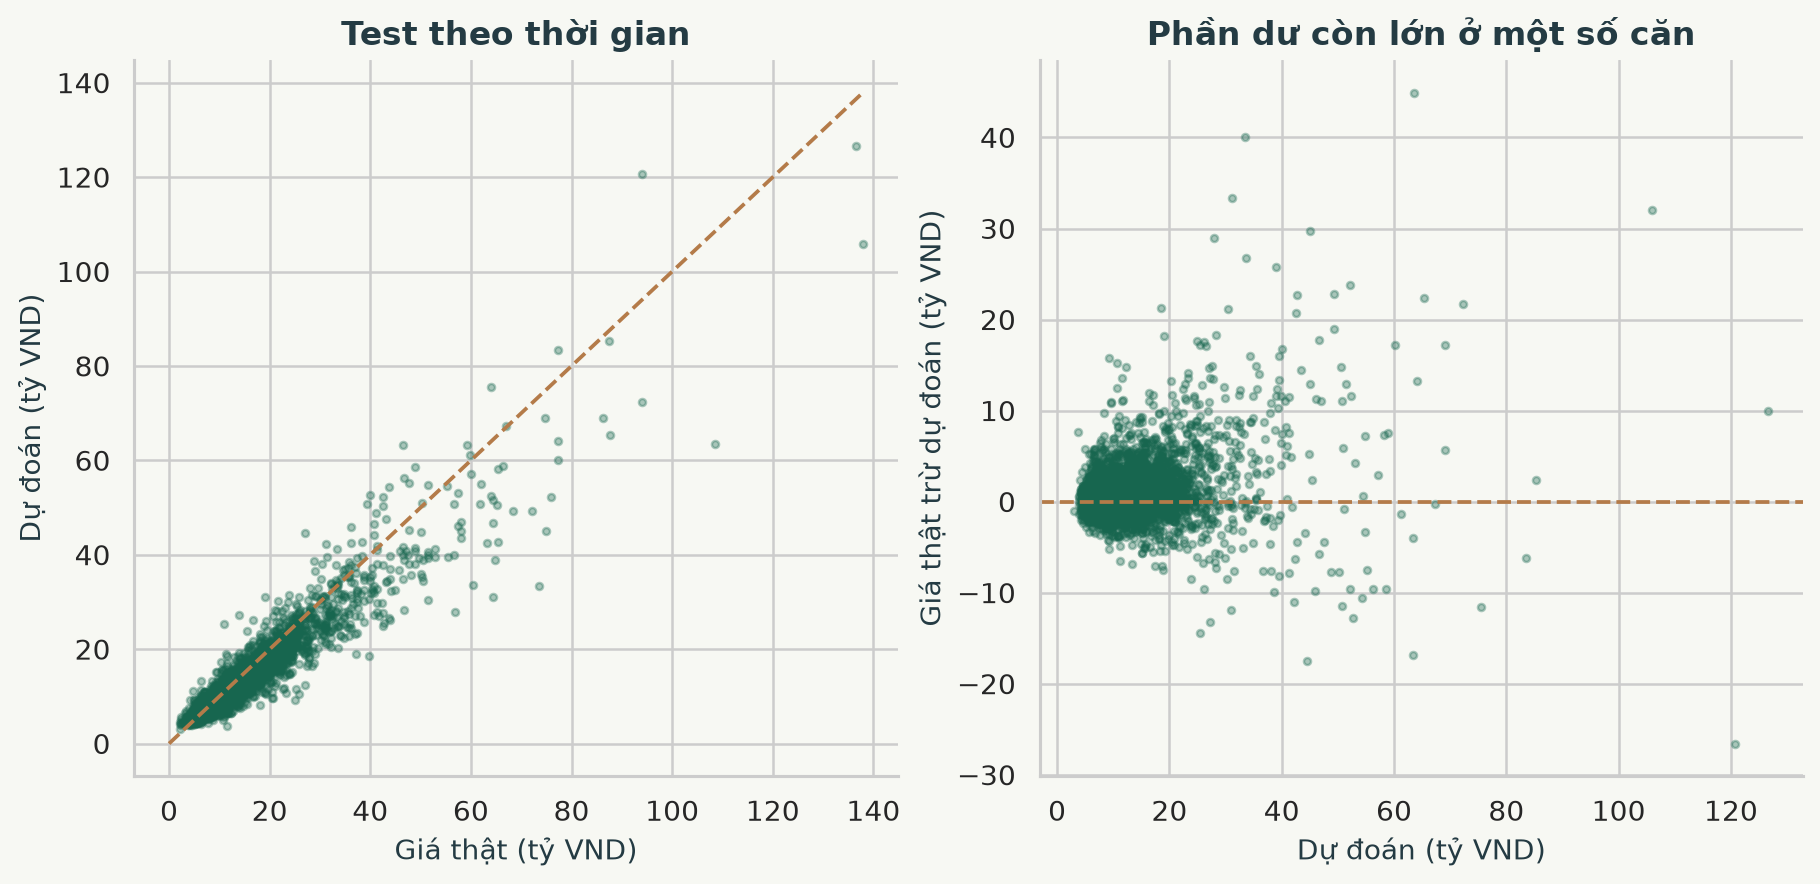

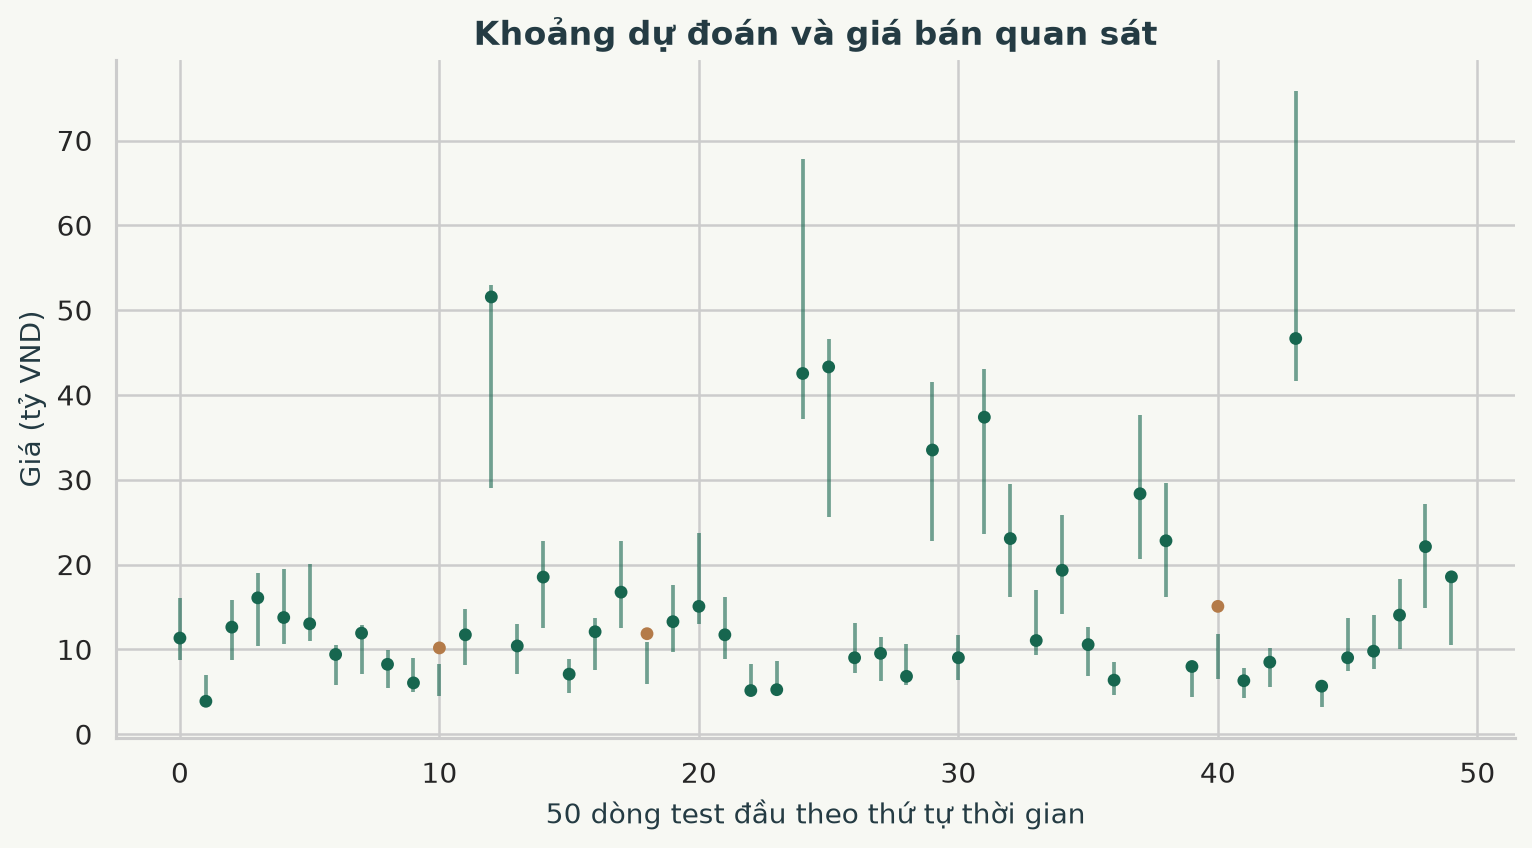

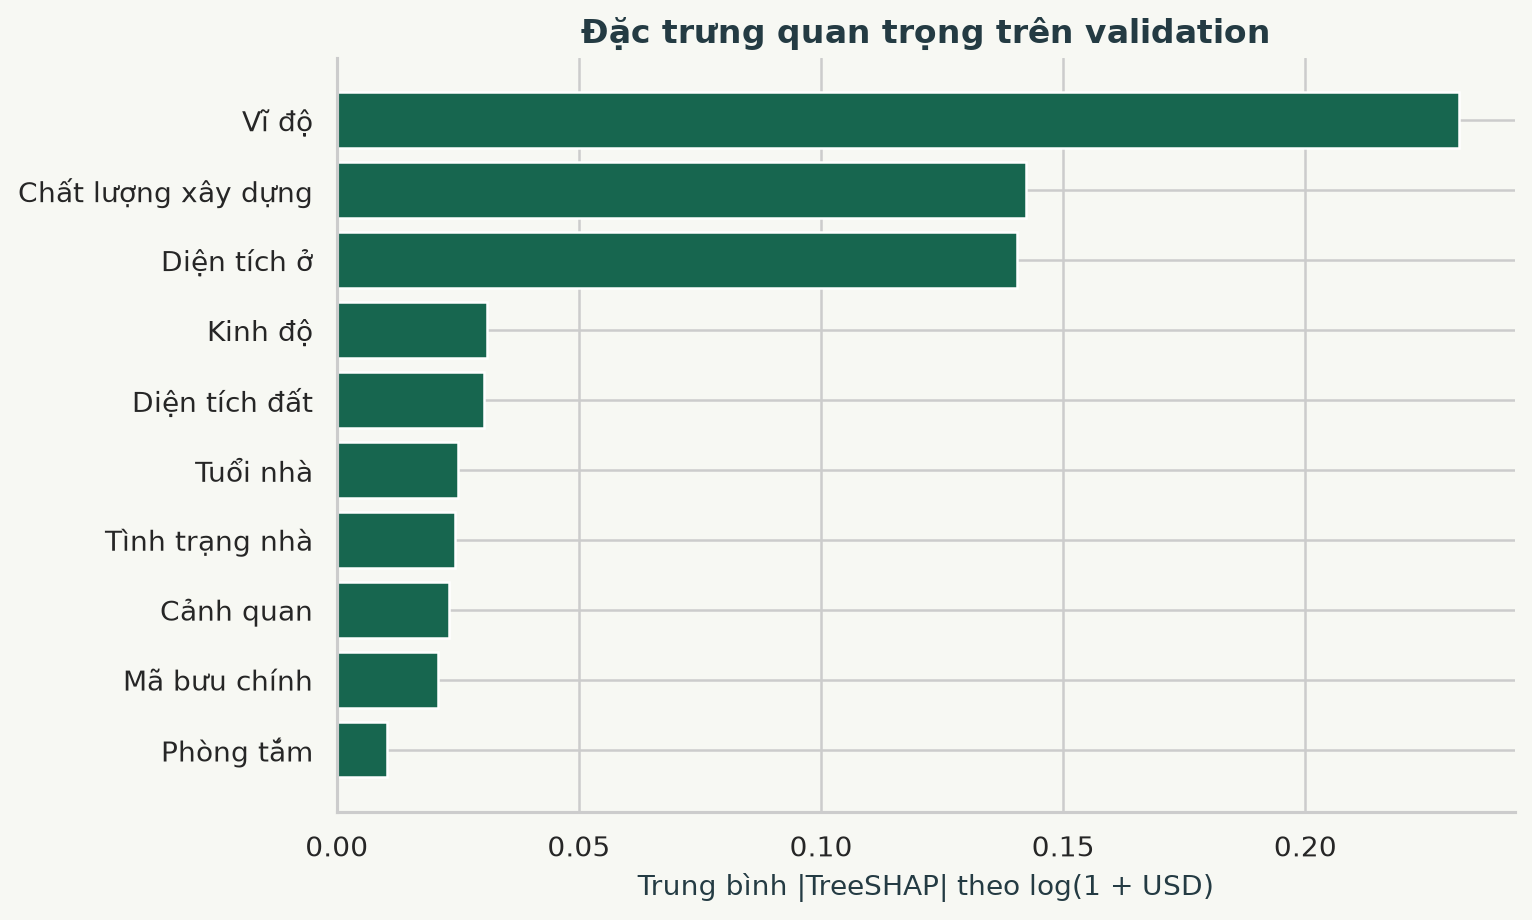

In [19]:
display(pd.DataFrame([integrated_metadata["test_metrics"], integrated_metadata["baseline_test_metrics"]], index=["Mô hình được chọn", "Median baseline"]))
for _chart in ["test_errors", "calibration", "importance"]:
    display(Image(filename=str(ARTIFACTS / "charts" / (_chart + ".png"))))

### 5 4 Giải thích một căn nhà trong tập test

Chọn căn có giá thật gần trung vị của test trước khi xem sai số, không lựa trường hợp dự đoán tốt. TreeSHAP phân rã chính xác dự đoán trên thang log(1 + USD). Các đóng góp cộng với mức nền để tái tạo đầu ra, không cộng trực tiếp thành các khoản VND và không được diễn giải là tác động nhân quả.

Các giao dịch đối chiếu phải đã bán trước ngày định giá và không cùng mã căn nhà đang xét. Giá/m² = giá dự đoán VND / diện tích ở m². Đây không phải một đơn giá cố định cho mọi căn.

living_m2            178.374
lot_m2            13,435.545
bedrooms               3.000
bathrooms              2.500
floors                 1.000
waterfront             0.000
view                   0.000
condition              3.000
grade                  8.000
latitude              47.268
longitude           -121.946
zipcode                98022
year_built              2014
year_renovated             0
sale_date         2015-03-03
id                3221079050
Name: Đầu vào, dtype: object

Giá thật USD                    465,000.000
Giá thật VND             11,987,700,000.000
Dự đoán VND              12,500,656,744.375
VND mỗi m² diện tích ở       70,081,223.618
Cận dưới VND              9,259,463,619.889
Cận trên VND             16,876,397,619.447
dtype: float64

,id,sale_date,living_m2,bedrooms,bathrooms,distance_km,price_usd,price_vnd,price_per_m2_vnd
0,2921079027,2014-09-24,201.600,4,2.500,1.719,"400,000.000","10,312,000,000.000","51,150,895.953"
1,2821079081,2014-10-10,231.329,4,2.000,1.365,"590,000.000","15,210,200,000.000","65,751,498.080"
2,3221079069,2014-08-15,257.341,3,2.500,1.357,"475,000.000","12,245,500,000.000","47,584,644.407"
3,3321079060,2014-10-20,242.477,3,1.750,1.923,"378,000.000","9,744,840,000.000","40,188,729.803"
4,0820079101,2014-12-22,189.522,3,2.250,3.948,"525,000.000","13,534,500,000.000","71,413,796.831"


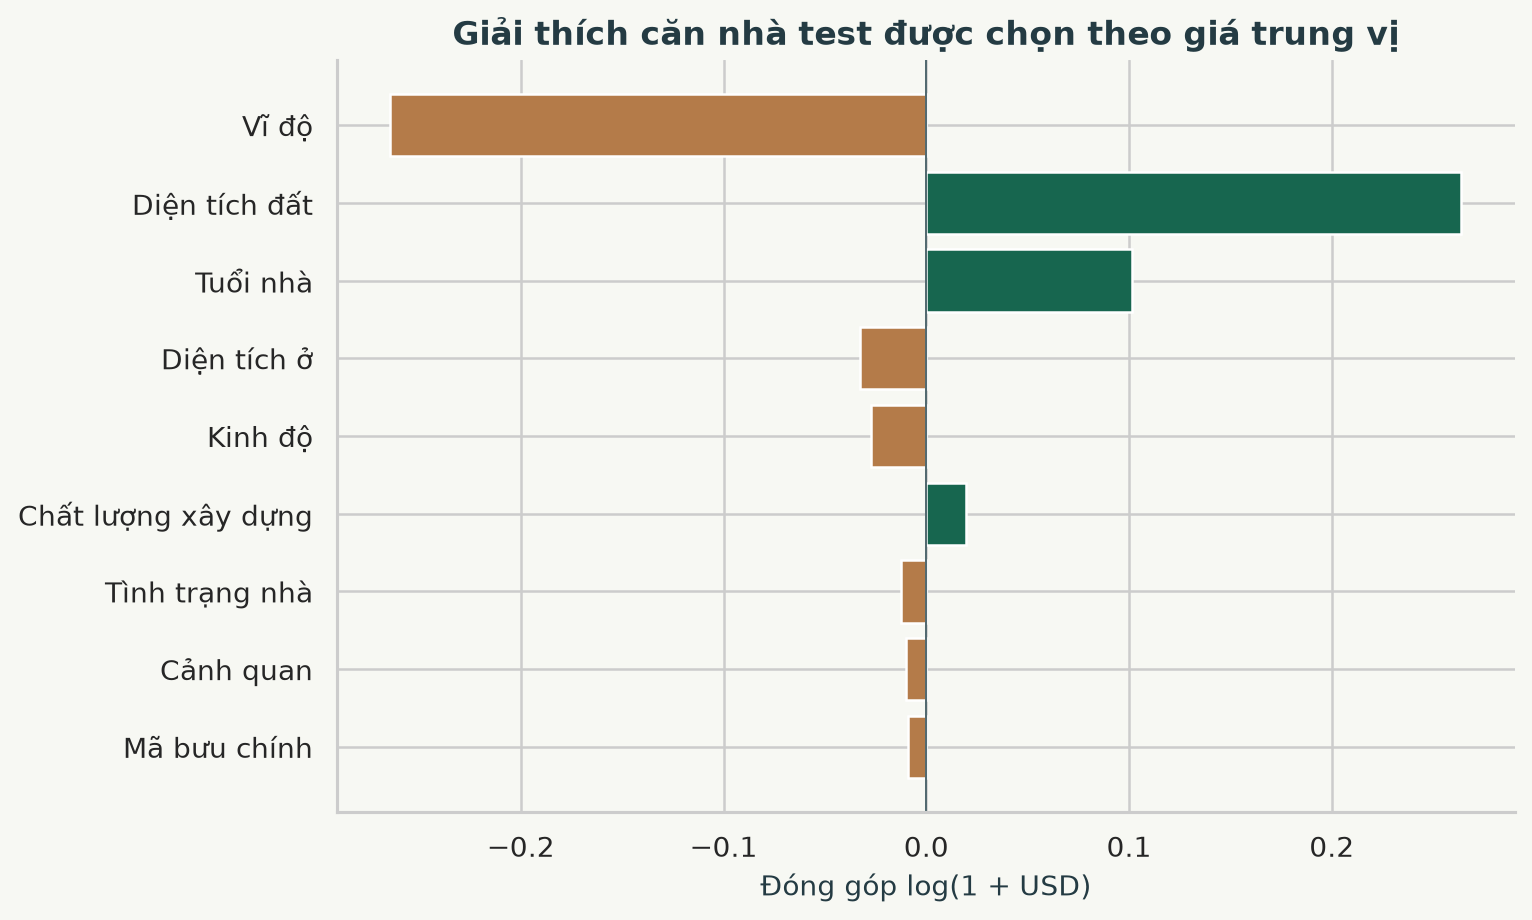

Tỷ giá và nguồn: {'usd_vnd': 25780.0, 'quote_kind': 'Vietcombank USD sell', 'source_url': 'https://portal.vietcombank.com.vn/Usercontrols/TVPortal.TyGia/pXML.aspx?b=1', 'source_page': 'https://www.vietcombank.com.vn/vi-VN/KHCN/Cong-cu-tien-ich/Ty-gia', 'quoted_at': '11/7/2026 12:39:49 AM', 'retrieved_at': '2026-11-06T17:41:58.606994+00:00', 'sha256': 'fa614c393979d637523813fffc2dcff9dd025cb681979f41ab363d3ef5e0c279', 'meaning': 'Currency conversion of historical US house prices; not a Vietnamese market valuation.'}
Ước tính nhà tại King County theo dữ liệu giao dịch 2014–2015, quy đổi sang VND. Không phải giá nhà Việt Nam hay định giá thị trường hiện tại. Quan hệ trong dữ liệu và đóng góp mô hình không chứng minh quan hệ nhân quả.


In [20]:
integrated_examples = json.loads((ARTIFACTS / "examples.json").read_text(encoding="utf-8"))
case = integrated_examples[0]
display(pd.Series(case["input"], name="Đầu vào"))
case_result = estimate_property(case["input"])
display(pd.Series({"Giá thật USD": case["actual_usd"], "Giá thật VND": case["actual_vnd"],
    "Dự đoán VND": case_result["predicted_vnd"], "VND mỗi m² diện tích ở": case_result["price_per_m2_vnd"],
    "Cận dưới VND": case_result["interval_vnd"][0], "Cận trên VND": case_result["interval_vnd"][1]}))
display(pd.DataFrame(case_result["comparables"]))
display(Image(filename=str(ARTIFACTS / "charts/example_explanation.png")))
print("Tỷ giá và nguồn:", integrated_metadata["exchange_rate"])
print(integrated_metadata["limitation"])

### 5 5 Chạy lại và nguồn tham chiếu

Từ `real_estate_ai`: `python -m backend.train_kingcounty --import-db` với `DB_BACKEND=sqlite`. Chạy `../scripts/build_kingcounty_evidence.py` để dựng lại biểu đồ. `../chay_ui.cmd` mở giao diện chính. Dữ liệu cũ được giữ trong bảng riêng, dataset theo giao dịch ở `kingcounty_sales` và lịch sử dự đoán ở `kingcounty_predictions`.

Nguồn: [Kaggle King County](https://www.kaggle.com/datasets/harlfoxem/housesalesprediction), [GeoDa mô tả biến](https://geodacenter.github.io/data-and-lab/KingCounty-HouseSales2015/), [Vietcombank](https://www.vietcombank.com.vn/vi-VN/KHCN/Cong-cu-tien-ich/Ty-gia), [OpenStreetMap và ODbL](https://www.openstreetmap.org/copyright), [scikit-learn về cross validation](https://scikit-learn.org/stable/modules/cross_validation.html), [XGBoost về dự đoán đóng góp](https://xgboost.readthedocs.io/en/stable/prediction.html).

## 6 Phân tích và dự đoán giá rao bán tại Việt Nam

Phần này đã chạy trong kernel mới; giữ nguyên kết quả các thí nghiệm tham khảo phía trước.


Nguyễn Duy Trường · MSSV 24150180 · Nhóm 8

Nguồn chính là House Price Prediction Dataset Vietnam 2024 của Nguyen Tien Nhan trên Kaggle, phiên bản 8. Price theo tỷ VND được nhân 1e9. Đây là giá rao bán, chưa phải giá giao dịch đã xác minh hoặc giá hiện tại. Nguồn không có ngày đăng từng tin hoặc cột loại nhà. Chia theo nhóm địa chỉ–diện tích; chưa kiểm thử theo thời gian. King County là thí nghiệm tham khảo riêng.

In [1]:
from pathlib import Path
import sys, json, hashlib, runpy
import numpy as np
import pandas as pd
from IPython.display import display, Image
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
project = next(p / "real_estate_ai" for p in [Path.cwd(), *Path.cwd().parents] if (p / "real_estate_ai/backend/vietnam.py").exists())
sys.path.insert(0,str(project))
from backend.vietnam import ARTIFACTS as VN_ART, FEATURES, normalize_features, load_bundle, estimate_property
provenance = json.loads((VN_ART / "clean_manifest.json").read_text(encoding="utf-8"))
assert hashlib.sha256((VN_ART / "listings_clean.csv.gz").read_bytes()).hexdigest() == provenance["sha256"]
vn_data = pd.read_csv(VN_ART / "listings_clean.csv.gz", dtype={"district_name":str,"ward_name":str})
vn_meta = load_bundle()["metadata"]
print(vn_meta["scope"])
display(pd.Series(vn_meta["audit"]).drop("optional_values_set_missing"))
print("Nguồn:",provenance["source"]["source_url"],"Revision:",provenance["source"]["revision"])

Giá rao bán tham khảo tại TP.HCM và Hà Nội, học từ House Price Prediction Dataset Vietnam 2024 của Nguyen Tien Nhan trên Kaggle, phiên bản 8. Giá nguồn theo tỷ VND được đổi sang VND. Không có ngày đăng từng tin; kết quả kiểm thử là chia ngẫu nhiên theo nhóm, chưa phải dự báo theo thời gian. Tên địa bàn theo địa chỉ nguồn; chưa xác minh giá chốt giao dịch hoặc giá hiện tại.


raw_rows                                                                      30229
raw_columns                                                                      12
files                                                                             1
in_scope_rows                                                                 22245
invalid_or_outside_price_scope                                                   62
exact_duplicate_rows_removed                                                      0
accepted_rows                                                                 22183
property_proxy_groups                                                         17035
rows_sharing_proxy                                                             5148
missing_fraction                  {'area': 0.0, 'bedroom_count': 0.1621511968624...
observed_price_billion_range                                            [1.0, 11.5]
deduplication                     Bỏ dòng trùng toàn bộ 12 cột. Khóa nhóm là

Nguồn: https://www.kaggle.com/datasets/nguyentiennhan/vietnam-housing-dataset-2024 Revision: kaggle-version-8


## 1 Sàng lọc đặc trưng và ngăn rò rỉ

Dataset có **12 cột**, gồm 11 cột dự báo ứng viên và nhãn Price. Loại Balcony direction vì thiếu trên 80% ở train; Address được tách thành ba nhóm địa bàn. Kết quả có **12 nhóm đầu vào**: 6 biến số và 6 nhóm danh mục, từ 10 cột nguồn được giữ. Không đưa giá hoặc giá/m² quan sát vào X. Các giá trị thiếu chỉ được điền bằng thống kê train. Khóa nhóm địa chỉ–diện tích không dùng giá; các dòng cùng khóa chỉ thuộc một tập.

,n,groups,first_date,last_date
train,13398.0,10220.0,NaN,NaN
validation,3271.0,2555.0,NaN,NaN
calibration,2196.0,1704.0,NaN,NaN
test,3318.0,2556.0,NaN,NaN


Đầu vào ứng viên: ['area', 'bedroom_count', 'bathroom_count', 'floor_count', 'frontage_width', 'road_width', 'province_name', 'district_name', 'ward_name', 'house_direction', 'legal_status', 'furniture_state']


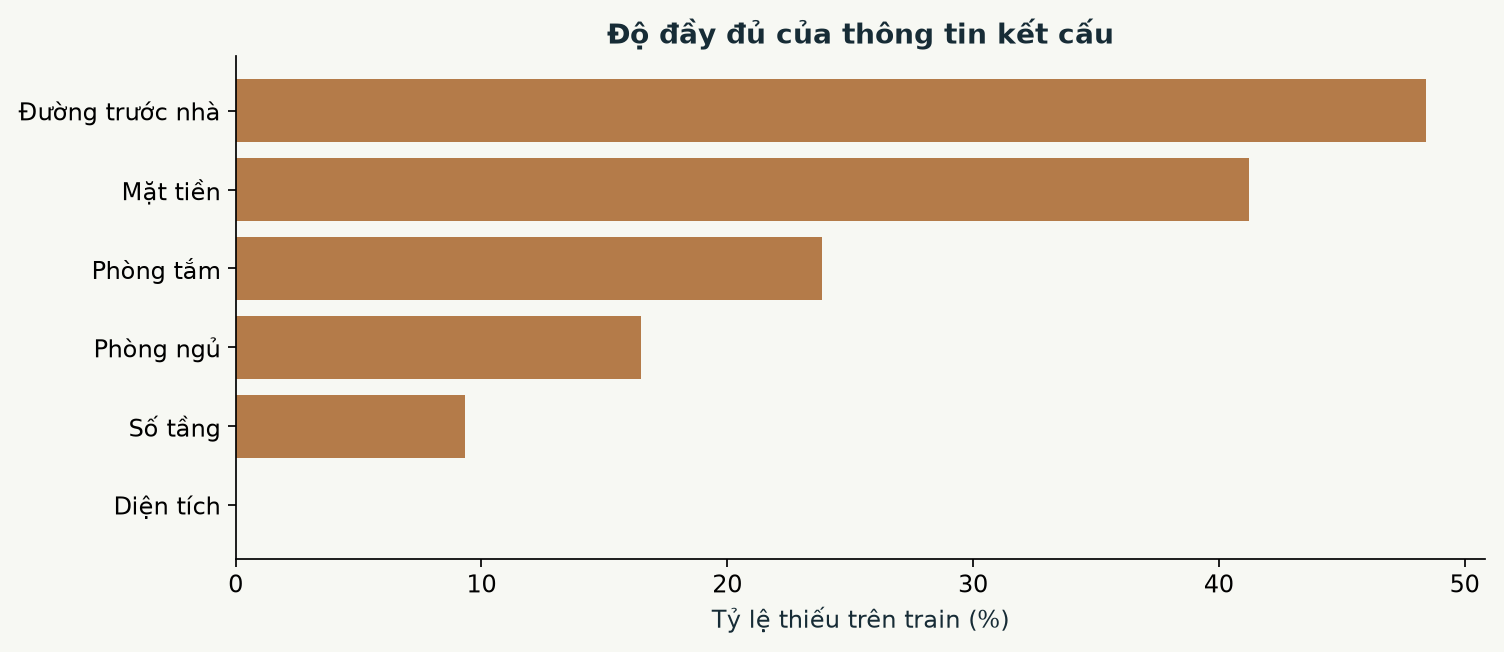

In [2]:
vn_split = json.loads((VN_ART / "split.json").read_text(encoding="utf-8"))
for i, left in enumerate(vn_split):
    for right in list(vn_split)[i+1:]:
        assert not set(vn_split[left]) & set(vn_split[right])
display(pd.DataFrame(vn_meta["splits"]).T)
print("Đầu vào ứng viên:",FEATURES)
display(Image(filename=str(VN_ART / "charts/missingness.png")))

## 2 Hồi quy tuyến tính và feature importance

OLS học log(VND), lấy log diện tích và chuẩn hóa sáu biến số. Các nhóm danh mục được one-hot. Độ quan trọng của một nhóm được đo bằng **mức tăng RMSE log trên validation khi bỏ nhóm đó và fit lại OLS**. Cách này so được cả số và danh mục, không xếp hạng hệ số thô có đơn vị khác nhau. Chỉ dùng train/validation để chọn biến; không dùng test.

Chạy lại phân tích dưới đây tái lập kết quả từ dữ liệu đã kiểm tra checksum. Hệ số có điều kiện, chưa chứng minh nhân quả.

OLS full {'rmse_log': 0.2451902863587861, 'rmse_vnd': 1460287622.9776614, 'r2_vnd': 0.5019053092190161, 'median_ape': 0.13778371116613475}


Without area 0.07175180701247402


Without

 bedroom_count 0.00013007255300870324


Without

 bathroom_count 0.0008589332363788948


... (8 outputs left out)

Without furniture_state -8.823699750581948e-07


Selected {'k': 6, 'features': ['area', 'district_name', 'floor_count', 'ward_name', 'legal_status', 'road_width'], 'validation': {'rmse_log': 0.24741566674956367, 'rmse_vnd': 1479939321.8116634, 'r2_vnd': 0.4884089677679029, 'median_ape': 0.1399497426379218}}


12 cột gốc gồm nhãn Price → 12 nhóm đầu vào sau xử lý → 166 cột thiết kế OLS


,label,delta_rmse_log,delta_rmse_vnd
0,Diện tích,7.175181e-02,3.212154e+08
1,Quận/huyện,3.907359e-02,1.344826e+08
2,Số tầng,9.681947e-03,5.249554e+07
3,Phường/xã,4.651458e-03,1.722498e+07
4,Pháp lý,2.923821e-03,4.358796e+06
5,Đường trước nhà,1.760181e-03,-4.853582e+06
6,Phòng tắm,8.589332e-04,5.908843e+06
7,Hướng nhà,1.481492e-04,9.628211e+05
8,Phòng ngủ,1.300726e-04,2.019866e+06
9,Mặt tiền,3.185399e-05,-3.187241e+05


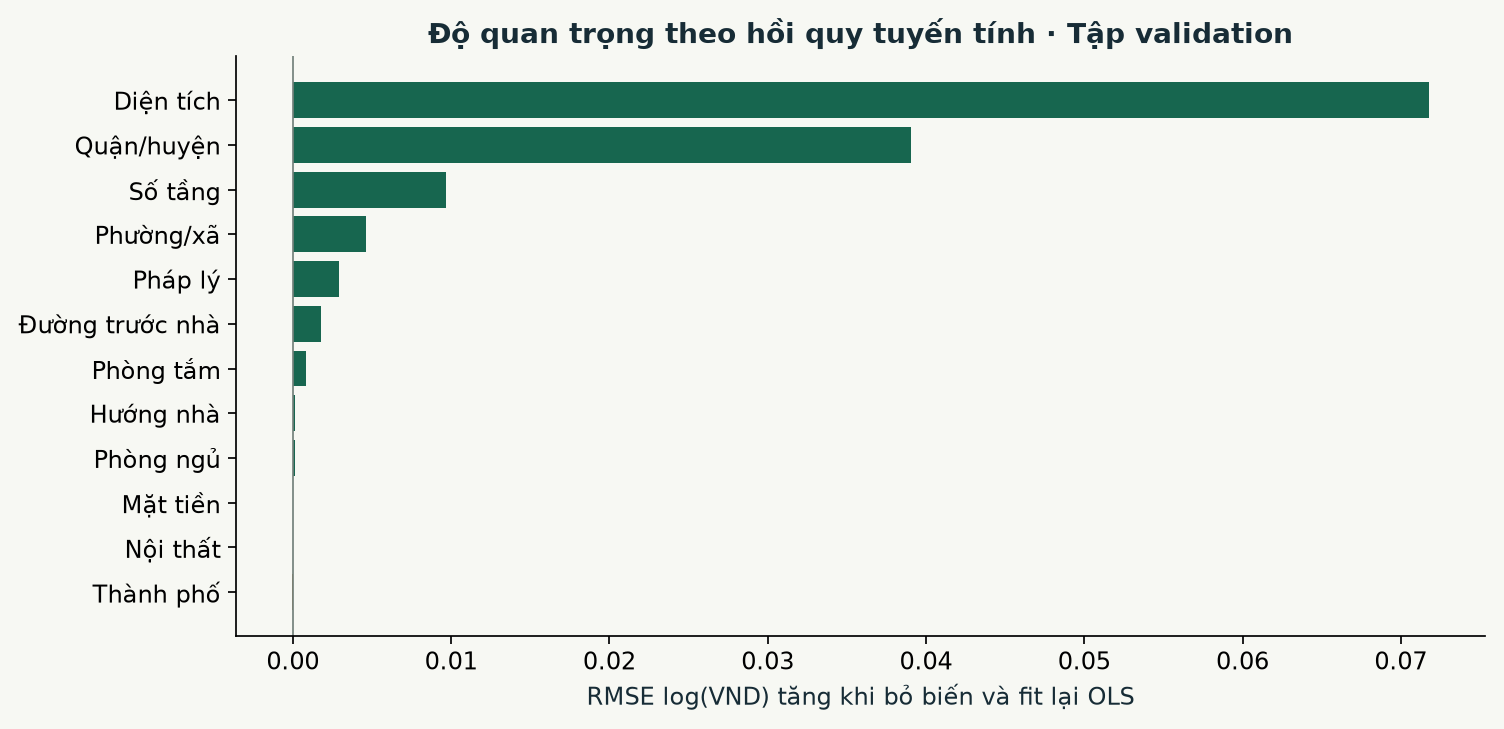

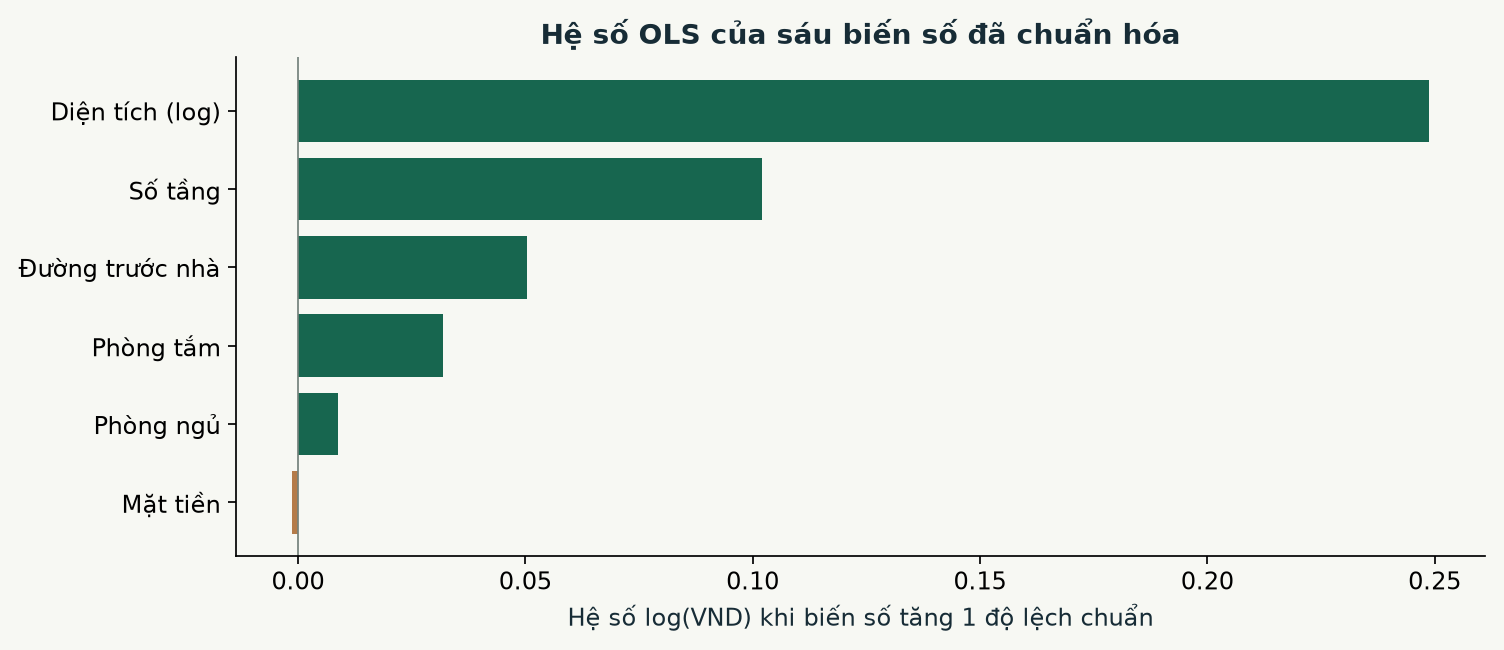

In [3]:
runpy.run_path(str(project.parent / "scripts/analyze_vietnam_linear.py"), run_name="__main__")
linear = json.loads((VN_ART / "linear_analysis.json").read_text(encoding="utf-8"))
print("12 cột gốc gồm nhãn Price →",linear["candidate_input_count"],"nhóm đầu vào sau xử lý →",linear["encoded_column_count"],"cột thiết kế OLS")
display(pd.DataFrame(linear["importance"])[["label","delta_rmse_log","delta_rmse_vnd"]])
display(Image(filename=str(VN_ART / "charts/linear_importance.png")))
display(Image(filename=str(VN_ART / "charts/linear_coefficients.png")))

## 3 Chọn số biến và lý do sử dụng

Chọn bộ nhỏ nhất trong các tiền tố thứ hạng có RMSE log không quá 1% so với bộ tốt nhất. Bộ lõi OLS có **6 biến**: diện tích, quận/huyện, số tầng, phường/xã, pháp lý và đường trước nhà. Diện tích mô tả quy mô; quận/phường mô tả vị trí; số tầng bổ sung kết cấu; pháp lý và chiều rộng đường bổ sung thông tin trong validation. Đây là liên hệ dự báo, chưa chứng minh nhân quả.

Số phòng tương quan với diện tích; thành phố có thông tin trùng quận/huyện. Ít thêm thông tin tuyến tính không có nghĩa là không liên quan đến giá. Ứng dụng phục vụ **XGBoost 12 đầu vào**, là mô hình phi tuyến riêng; chưa so XGBoost sáu biến với XGBoost 12 biến.

,rmse_log,rmse_vnd,r2_vnd,median_ape
k,,,,
1,0.361496,1.931851e+09,0.128269,0.221027
2,0.280360,1.612468e+09,0.392680,0.164899
3,0.256849,1.497288e+09,0.476344,0.151612
4,0.252259,1.481220e+09,0.487523,0.144335
5,0.249355,1.475616e+09,0.491394,0.143955
6,0.247416,1.479939e+09,0.488409,0.139950
7,0.245492,1.463331e+09,0.499827,0.137915
8,0.245323,1.462324e+09,0.500515,0.136418
9,0.245200,1.460184e+09,0.501976,0.138309


Bộ chọn: ['area', 'district_name', 'floor_count', 'ward_name', 'legal_status', 'road_width']


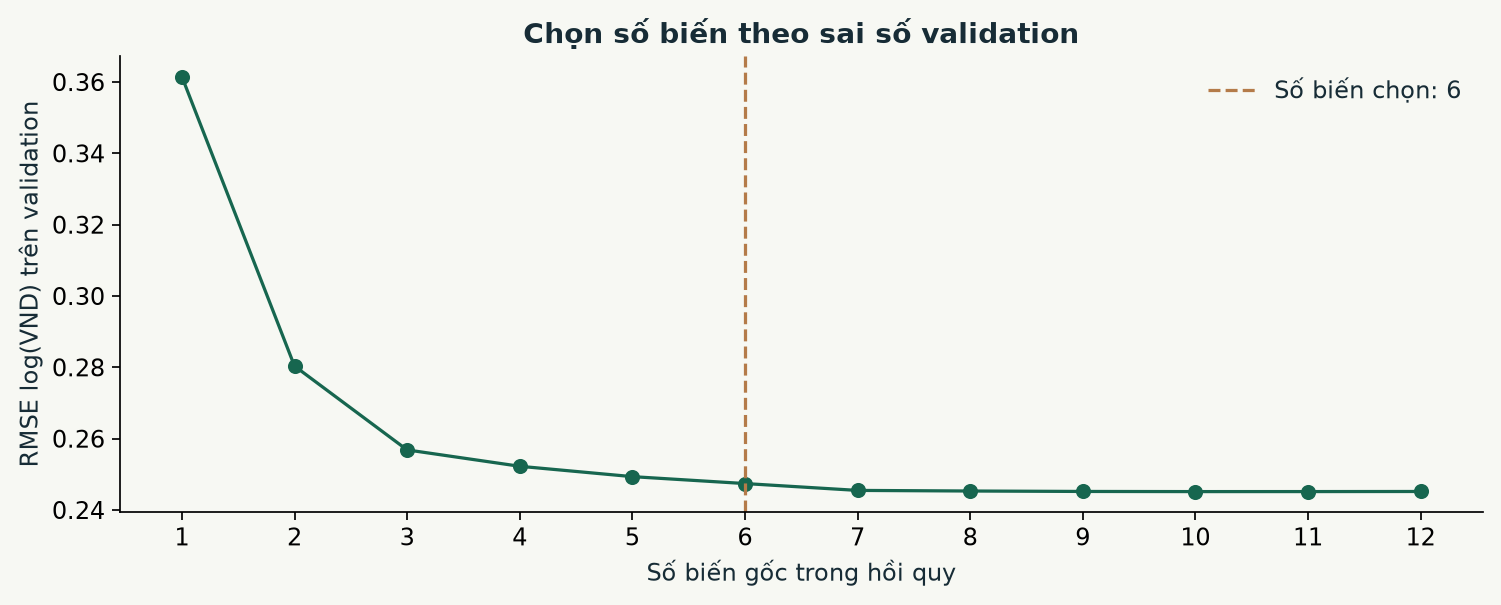

In [4]:
display(pd.DataFrame([{**row["validation"],"k":row["k"]} for row in linear["subsets"]]).set_index("k"))
print("Bộ chọn:",linear["selected"]["features"])
display(Image(filename=str(VN_ART / "charts/linear_selection.png")))

## 4 Biểu đồ về diện tích phòng và vị trí

Khám phá chỉ dùng train. Nguồn không có cột loại nhà nên các biểu đồ gộp bất động sản theo dataset. Trung vị giữa nhóm thể hiện quan hệ quan sát, không phải khoản tiền cộng cố định khi tăng một phòng. Đơn giá dùng diện tích khai báo, có thể là đất hoặc sàn tùy tin.

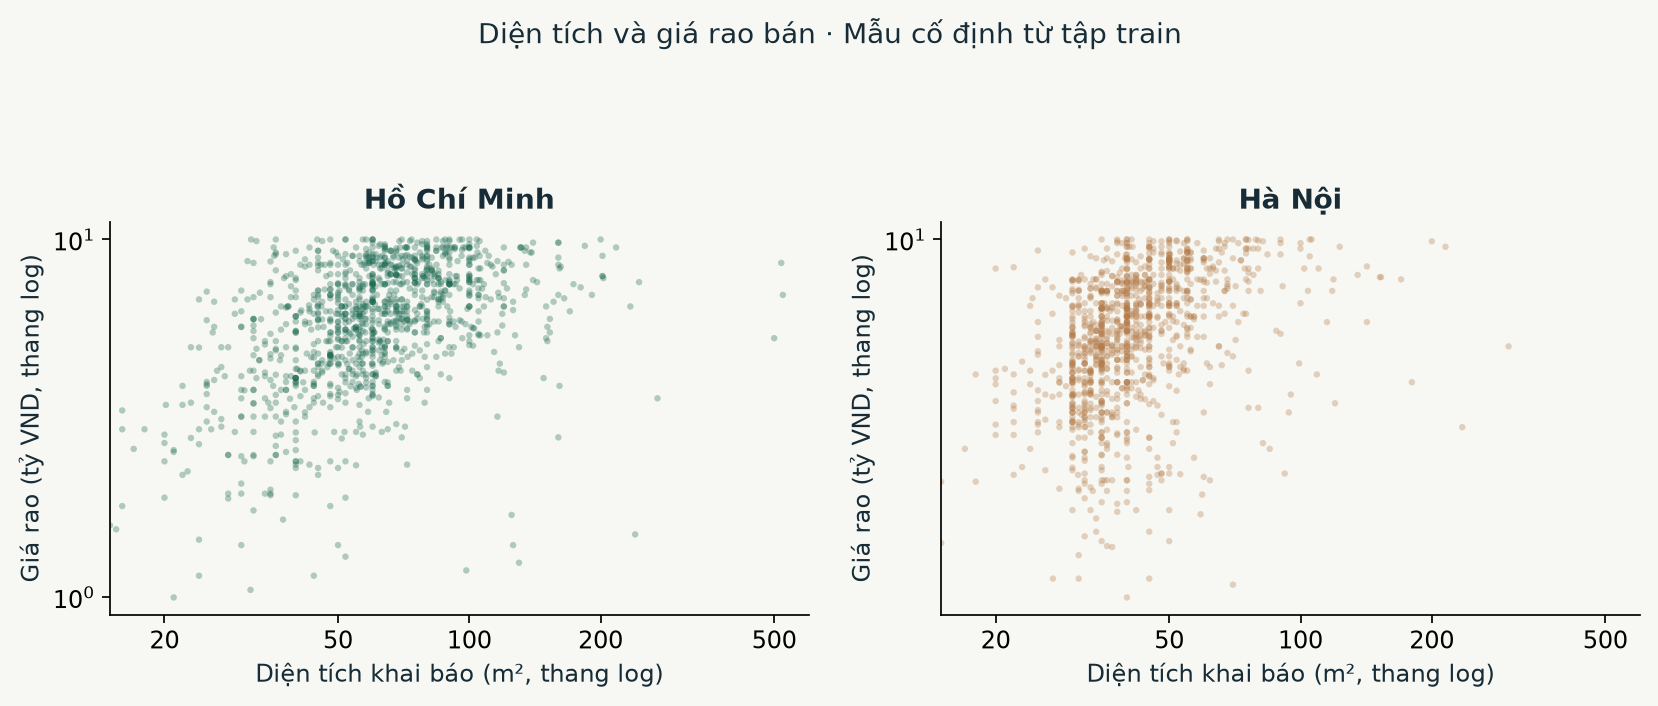

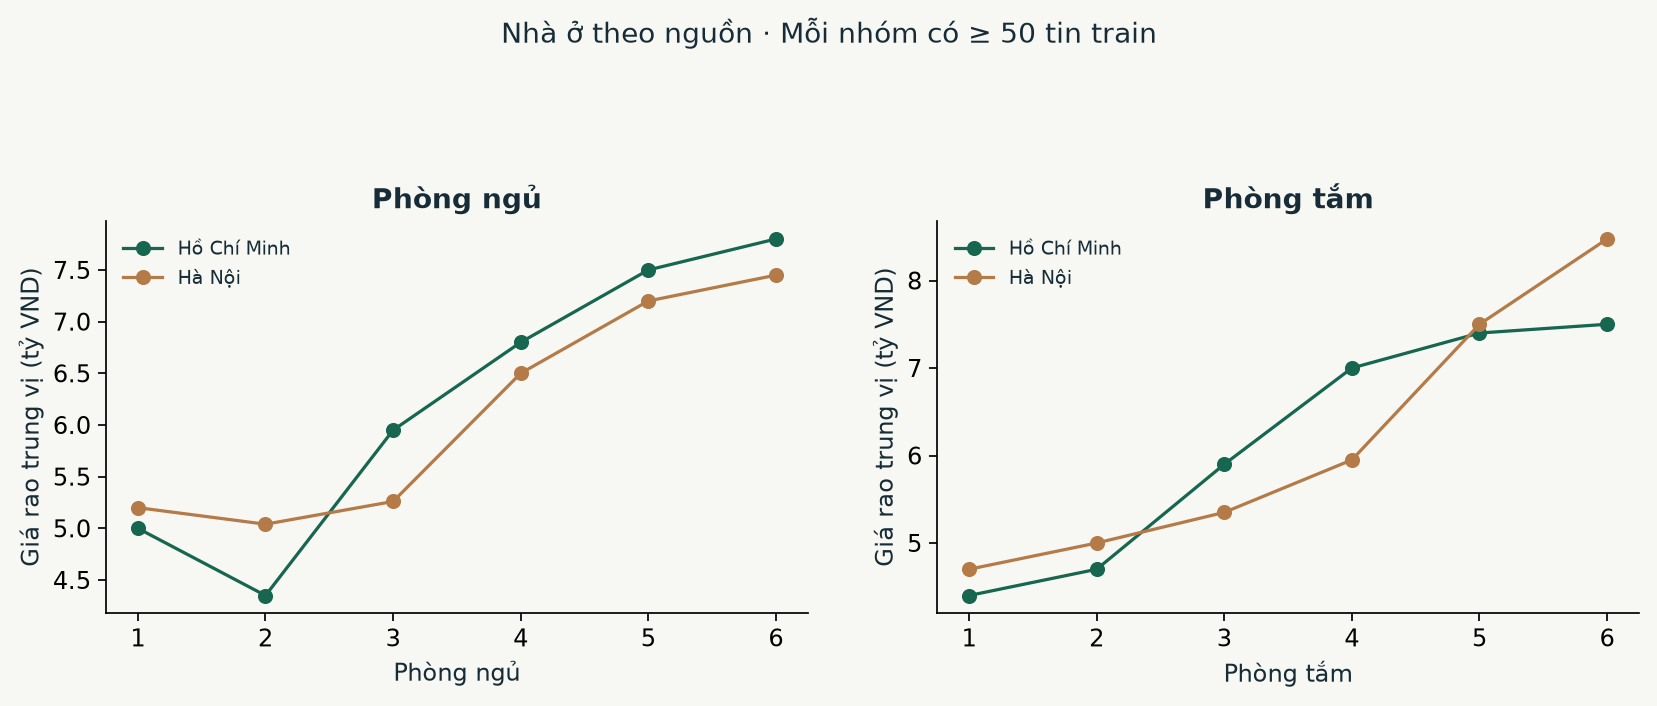

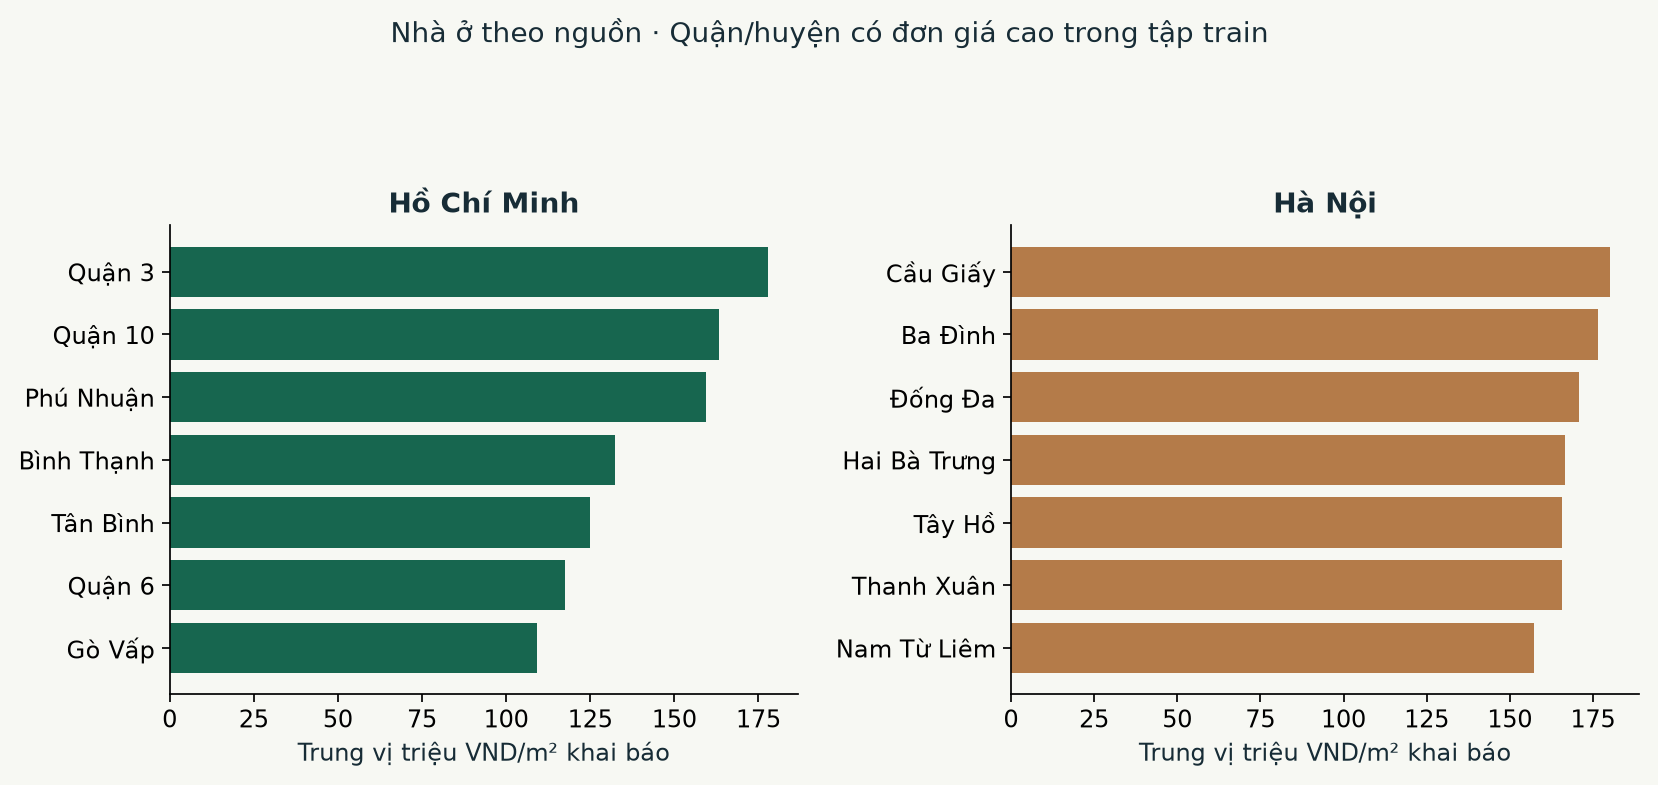

In [5]:
for chart in ["area_price","rooms","districts"]:
    display(Image(filename=str(VN_ART / "charts" / (chart+".png"))))

## 5 So sánh mô hình và kiểm thử cuối

XGBoost được chọn bằng validation, rồi fit train + validation. Calibration chỉ dùng hiệu chỉnh khoảng; test không chung nhóm địa chỉ–diện tích với phần fit. Không có ngày đăng để khẳng định test ở thời kỳ mới hơn. Các con số dưới đây được tính lại từ dự đoán của mô hình đã khóa.

,model,n,mae_vnd,rmse_vnd,r2,median_ape,within_20pct
0,Trung vị VND/m² theo khu vực,3271,1.466690e+09,2.621297e+09,-0.604973,0.175556,0.550902
1,XGBoost chưa dùng địa bàn,3271,1.232473e+09,1.579724e+09,0.417095,0.165109,0.585754
2,XGBoost thêm địa bàn,3271,9.390470e+08,1.242913e+09,0.639159,0.124600,0.721186


MAE VND       9.230267e+08
RMSE VND      1.225120e+09
R2 VND        6.435709e-01
MdAPE         1.207619e-01
Trong ±20%    7.287523e-01
dtype: float64

,dimension,label,n,mae_vnd,rmse_vnd,r2,median_ape,within_20pct,coverage_90
0,province_name,Hà Nội,1591,9.382583e+08,1.242672e+09,0.612360,0.125595,0.711502,0.902577
1,province_name,Hồ Chí Minh,1727,9.089946e+08,1.208724e+09,0.668619,0.117356,0.744644,0.890562


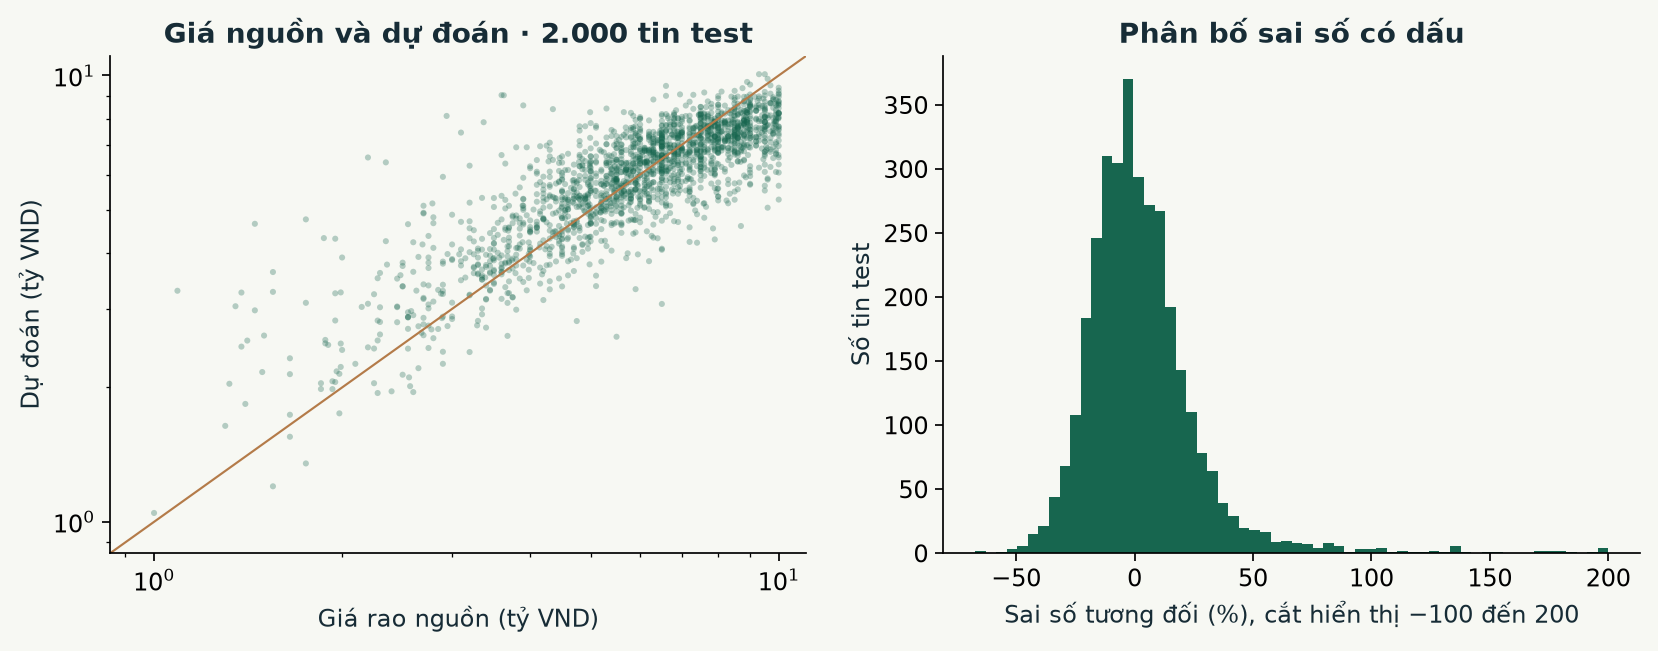

In [6]:
display(pd.DataFrame(vn_meta["validation_comparison"]))
vn_test = pd.read_csv(VN_ART / "test_predictions.csv", dtype={"district_name":str,"ward_name":str})
vn_pred = np.exp(load_bundle()["pipeline"].predict(normalize_features(vn_test)).astype(float))
assert np.allclose(vn_pred,vn_test.predicted_vnd,rtol=1e-6)
ape = np.abs(vn_pred - vn_test.price)/vn_test.price
display(pd.Series({"MAE VND":mean_absolute_error(vn_test.price,vn_pred),
                   "RMSE VND":np.sqrt(mean_squared_error(vn_test.price,vn_pred)),
                   "R2 VND":r2_score(vn_test.price,vn_pred),"MdAPE":np.median(ape),
                   "Trong ±20%":np.mean(ape<=.2)}))
display(pd.DataFrame(vn_meta["test_breakdown"]))
display(Image(filename=str(VN_ART / "charts/test_errors.png")))

## 6 Giải thích một căn nhà tại TP.HCM và Hà Nội

Chọn tin test có giá nguồn ở trung vị nhóm khai báo đủ phòng, trước khi xem sai số. TreeSHAP cộng trên log(VND), sau đó lấy hàm mũ để tái tạo dự đoán. Không diễn giải các thanh thành khoản VND cộng trực tiếp. Các tin đối chiếu từ train + validation, chưa phải giao dịch đã bán.

Hà Nội · Hà Đông {'area': 31.0, 'bedroom_count': 4.0, 'bathroom_count': 4.0, 'floor_count': 5.0, 'frontage_width': 3.3, 'road_width': 2.5, 'province_name': 'Hà Nội', 'district_name': 'Hà Đông', 'ward_name': 'Phường Vạn Phúc', 'house_direction': 'Tây - Nam', 'legal_status': 'Have certificate', 'furniture_state': 'Basic', 'reference_id': '0131f4af270516027cdc5f07'}


Giá rao nguồn VND                              5800000000.0
Giá dự đoán VND                           5209902510.762404
VND/m² khai báo                            168061371.314916
Khoảng 90%           [3770236464.159106, 7199305515.629577]
dtype: object

,feature,label,log_contribution
0,area,Diện tích,-0.261093
1,ward_name,Phường/xã,0.135309
2,road_width,Đường trước nhà,-0.096432
3,floor_count,Số tầng,0.056050
4,bathroom_count,Phòng tắm,0.022008
5,district_name,Quận/huyện,0.021410
6,furniture_state,Nội thất,-0.012969
7,bedroom_count,Phòng ngủ,0.011461
8,province_name,Thành phố,0.010007
9,legal_status,Pháp lý,0.006046


,listing_id,group_id,published_at,district_name,ward_name,area,bedroom_count,bathroom_count,price
0,ea0d61d945b1c55c55f9a415,4559aab5fe9409776e39de44,None,Hà Đông,Phường Vạn Phúc,31.0,4.0,4.0,6.200000e+09
1,fe7b33bc4e0542f1d23f226b,1c69e26058440766aeffa570,None,Hà Đông,Phường Vạn Phúc,31.0,4.0,4.0,6.100000e+09
2,2b35588faa42f070130d2b7b,f228a764da1a016f567dda59,None,Hà Đông,Phường Vạn Phúc,30.0,4.0,4.0,7.200000e+09
3,6339f909ead661196c094e94,e28b863161ffad9dfeae0e7d,None,Hà Đông,Phường Vạn Phúc,30.0,4.0,4.0,5.500000e+09
4,b0261794a1504be133b9232b,13aba4fc3e2828fb17be8427,None,Hà Đông,Phường Vạn Phúc,33.0,4.0,4.0,5.980000e+09


Hồ Chí Minh · Quận 2 {'area': 52.0, 'bedroom_count': 5.0, 'bathroom_count': 3.0, 'floor_count': 4.0, 'frontage_width': None, 'road_width': 5.0, 'province_name': 'Hồ Chí Minh', 'district_name': 'Quận 2', 'ward_name': 'Phường Bình Trưng Tây', 'house_direction': 'Không rõ', 'legal_status': 'Không rõ', 'furniture_state': 'Không rõ', 'reference_id': '801aaeca1aaba2e98c5dfb7c'}


Giá rao nguồn VND                              6300000000.0
Giá dự đoán VND                           6560432932.099627
VND/m² khai báo                            126162171.771147
Khoảng 90%           [4747571266.482813, 9065536427.105074]
dtype: object

,feature,label,log_contribution
0,floor_count,Số tầng,0.040667
1,area,Diện tích,0.036412
2,district_name,Quận/huyện,0.034123
3,bedroom_count,Phòng ngủ,0.019562
4,ward_name,Phường/xã,0.012730
5,legal_status,Pháp lý,-0.008760
6,province_name,Thành phố,-0.005762
7,frontage_width,Mặt tiền,-0.005678
8,bathroom_count,Phòng tắm,0.004988
9,road_width,Đường trước nhà,-0.002752


,listing_id,group_id,published_at,district_name,ward_name,area,bedroom_count,bathroom_count,price
0,5643eaf9cb936cf9614c2857,8008aadbeb9f0e4b42c52753,None,Quận 2,Phường Bình Trưng Tây,52.0,5.0,5.0,6.600000e+09
1,3e52134e8b21aec8388151ae,7d76ad40e6ead3548f41319b,None,Quận 2,Phường Bình Trưng Tây,51.5,3.0,3.0,6.300000e+09
2,37f3a589a0754e0da1811344,74d02bbbf648fb7f1d854909,None,Quận 2,Phường Bình Trưng Tây,51.5,4.0,4.0,6.300000e+09
3,adcbf3e64a9a12027d1441e9,8ee988cecfc61068a8a5c5a0,None,Quận 2,Phường Bình Trưng Tây,50.4,4.0,4.0,8.200000e+09
4,4971c72f000dccba5a6f724e,4389347b7c67153a16a10e32,None,Quận 2,Phường Bình Trưng Tây,60.0,5.0,4.0,8.200000e+09


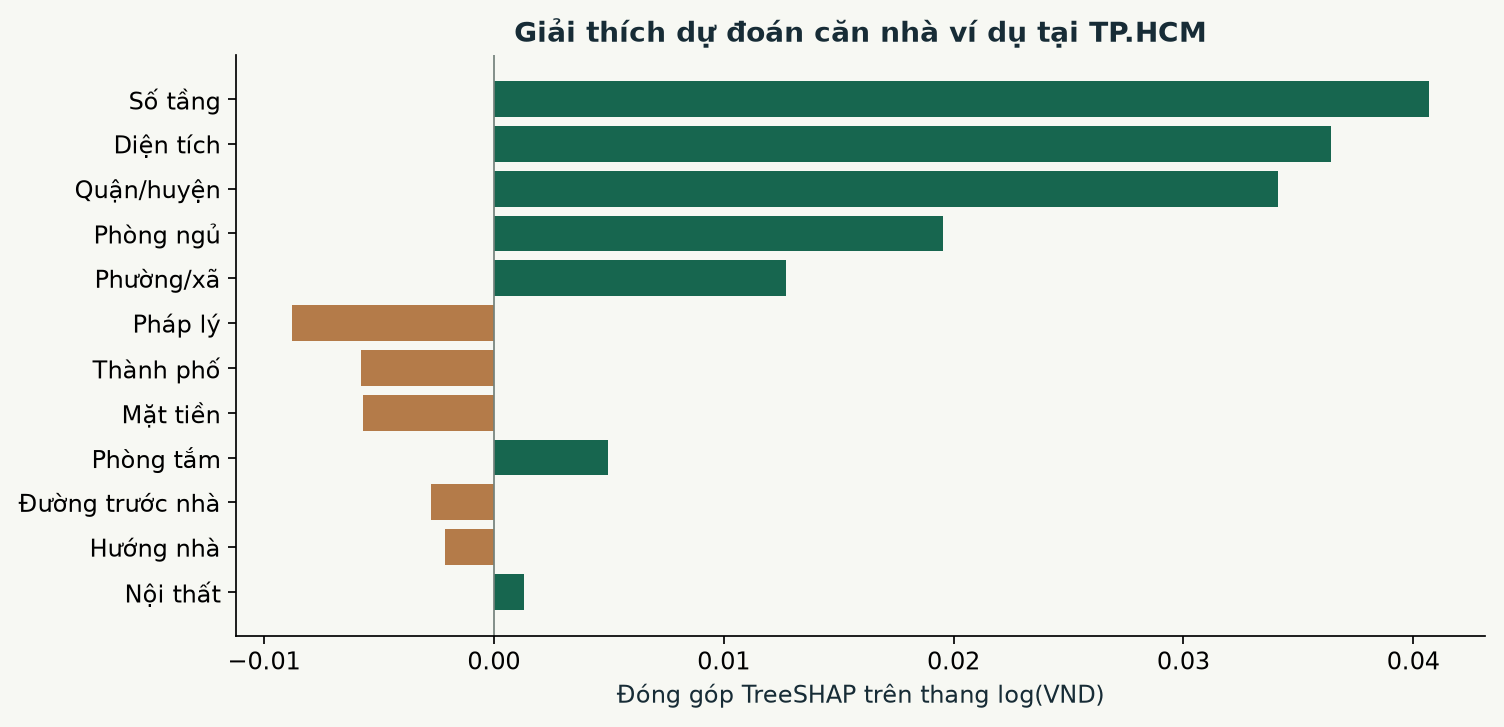

In [7]:
vn_examples = json.loads((VN_ART / "examples.json").read_text(encoding="utf-8"))
for case in vn_examples:
    result = estimate_property(case["input"])
    reconstructed = np.exp(result["base_log_vnd"] + sum(x["log_contribution"] for x in result["explanations"]))
    assert np.isclose(result["predicted_vnd"], reconstructed, rtol=5e-5)
    print(case["label"],case["input"])
    display(pd.Series({"Giá rao nguồn VND":case["asking_vnd"],"Giá dự đoán VND":result["predicted_vnd"],
                       "VND/m² khai báo":result["price_per_m2_vnd"],"Khoảng 90%":result["interval_90_vnd"]}))
    display(pd.DataFrame(result["explanations"]))
    display(pd.DataFrame(result["comparables"]))
display(Image(filename=str(VN_ART / "charts/example_explanation.png")))

## 7 Giới hạn và cách chạy

Nguồn chưa có tọa độ hoặc khoảng cách trường học/cửa hàng được xác minh, nên mô hình không dùng những biến này. Chưa có mã nhà thật, ngày đăng hoặc loại nhà; giá là giá rao; diện tích khai báo có thể chưa đồng nhất. Giá nguồn giữ lại từ 1 đến 11,5 tỷ VND; không suy rộng chất lượng sang phân khúc cao hơn. Khoảng 90% gộp không bảo đảm độ phủ từng thành phố.

Chạy `TieuLuan_CuoiKy/chay_ui.cmd`, mở http://127.0.0.1:8000. King County tham khảo tại `/kingcounty`. Huấn luyện lại Việt Nam: `scripts/huan_luyen.cmd`. Dữ liệu và model nằm trong `real_estate_ai/artifacts/vietnam/`. Không dùng dự đoán của người dùng làm nhãn huấn luyện.

Nguồn: [Nguyen Tien Nhan trên Kaggle](https://www.kaggle.com/datasets/nguyentiennhan/vietnam-housing-dataset-2024), phiên bản 8, CC0 Public Domain; [LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html); [XGBoost prediction](https://xgboost.readthedocs.io/en/stable/prediction.html).